# PROJEK JARINGAN SYARAF TIRUAN (JST)
## Prediksi Intensitas Kebakaran Hutan (Fire Radiative Power / FRP) di Kalimantan Menggunakan Data Riil Satelit NASA FIRMS (VIIRS 375m)

### Konteks & Latar Belakang Masalah
Kebakaran hutan dan lahan (karhutla) di Kalimantan menimbulkan dampak ekologis, kerugian ekonomi, gangguan kesehatan lintas wilayah, serta ancaman keselamatan bagi personel pemadaman di lapangan (seperti insiden helikopter water-bombing di Seruyan, Kalteng).

Satelit **Suomi-NPP** dengan sensor **VIIRS (Visible Infrared Imaging Radiometer Suite)** mendeteksi anomali termal aktif. Energi termal yang dilepaskan dikuantifikasi sebagai **Fire Radiative Power (FRP)** dalam MegaWatt (MW), indikator utama keganasan kobaran api.

Model yang dibangun: **Jaringan Syaraf Tiruan (JST) - Multilayer Perceptron (MLP)** berbasis **PyTorch** (CUDA bila tersedia).

### Ringkasan Perubahan (audit & Tahap 2)
| # | Perubahan | Alasan / dampak |
|---|---|---|
| 1 | **Split berkelompok** per overpass × sel 0,5°, plus GroupKFold, *forward-chaining*, dan uji waktu | Split acak bocor: 29,6% titik uji punya tetangga di data latih dengan FRP **identik** (tinggal 0,4%) |
| 2 | Flag piksel I4 **terlipat (208 K)** / jenuh (367 K) dan batas atas keluaran | Mencegah prediksi ribuan MW untuk api ekstrem |
| 3 | Fitur kerapatan **per overpass**; `day_idx` dihapus | Tidak ada informasi dari overpass ±12 jam ke depan |
| 4 | **11 fitur klaster api** (piksel tetangga 0,5 & 1 km) | Penyumbang perbaikan terbesar: MAE 4,13 → 3,80 MW, R² skala log 0,64 → 0,72 (studi ablasi) |
| 5 | **Hyperparameter tuning** bertahap (aktivasi, arsitektur, learning rate, batch size) | Terpilih SiLU, 256-128-64, lr 0,001, batch 128 |
| 6 | **Ensemble 5 seed** + sebaran skor antar-seed | R² per seed 0,351 ± 0,009; ensemble 0,355 |
| 7 | **Ambang alarm CRITICAL** dituning di validasi | Recall CRITICAL 31,0% → 66,2% |
| 8 | Pembanding baseline (konstan, regresi linear), XGBoost, dan **studi ablasi** dari desain Tahap 1 | Kontribusi tiap perubahan terukur |

### Hasil (data uji berkelompok, 6.729 sampel)
| Model | MSE | RMSE (MW) | MAE (MW) | R² | R² (skala log) |
|---|---|---|---|---|---|
| Baseline: rata-rata data latih | 188,79 | 13,74 | 6,42 | 0,000 | −0,287 |
| Baseline: regresi linear (log1p) + isotonic | 133,40 | 11,55 | 4,04 | 0,293 | 0,685 |
| XGBoost (tweedie) | 128,38 | 11,33 | 3,74 | 0,320 | 0,714 |
| **JST ensemble 5 seed + isotonic (model final)** | **121,81** | **11,04** | **3,76** | **0,355** | **0,721** |

In [1]:
# 1. Import Library Utama & Konfigurasi Komputasi
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split, GroupShuffleSplit, GroupKFold, KFold
from sklearn.neighbors import BallTree
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, confusion_matrix

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch Version  : {torch.__version__}')
print(f'Komputasi Device : {device.type.upper()}')
if device.type == 'cuda':
    print(f'Nama GPU         : {torch.cuda.get_device_name(0)}')
    print(f'Alokasi Memori   : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB')

PyTorch Version  : 2.15.0+cu132
Komputasi Device : CPU


### 2. Memuat Dataset Riil NASA FIRMS (Kalimantan)

Dataset bersih berisi 35.826 titik api. Kolom `acq_time`, `acq_date`, dan `daynight` diambil dari file mentah dan diselaraskan baris demi baris (satu baris FRP 529,28 MW telah dibuang pada tahap *cleaning*).

Setiap baris juga diberi ID **overpass** (tanggal UTC + siang/malam). Satu overpass = satu lintasan satelit; seluruh deteksi dalam satu overpass tersedia pada saat yang sama, sedangkan overpass berikutnya baru ada ±12 jam kemudian.

In [2]:
raw = pd.read_csv('nasa_viirs_kalimantan_raw.csv')
cleaned = pd.read_csv('data_karhutla_kalimantan_cleaned.csv')

raw = raw[raw['frp'] < 500].reset_index(drop=True)
assert len(raw) == len(cleaned), 'panjang data mentah dan bersih tidak sama'
assert np.allclose(raw['frp'].values, cleaned['frp'].values), 'urutan baris tidak selaras'

df = cleaned.copy()
df['acq_time'] = raw['acq_time'].values          # UTC, format HHMM
df['acq_date'] = pd.to_datetime(raw['acq_date'].values)
df['day_idx'] = (df['acq_date'] - df['acq_date'].min()).dt.days
df['daynight'] = raw['daynight'].values
df['overpass'] = df['acq_date'].dt.strftime('%Y-%m-%d') + '_' + df['daynight']

print(f'Ukuran dataset: {df.shape[0]:,} baris data dan {df.shape[1]} kolom.')
print(f'Periode data  : {df["acq_date"].min().date()} s/d {df["acq_date"].max().date()} '
      f'({df["day_idx"].nunique()} hari, {df["overpass"].nunique()} overpass)')
df.head()

Ukuran dataset: 35,826 baris data dan 14 kolom.
Periode data  : 2026-10-18 s/d 2026-11-01 (15 hari, 29 overpass)


,latitude,longitude,bright_ti4,scan,track,bright_ti5,is_day,confidence_score,frp,acq_time,acq_date,day_idx,daynight,overpass
0,-2.97735,110.81212,335.33,0.41,0.37,303.09,1,2,3.33,622,2026-10-18,0,D,2026-10-18_D
1,-2.97506,110.80424,367.00,0.41,0.37,307.10,1,3,8.11,622,2026-10-18,0,D,2026-10-18_D
2,-2.97393,110.81159,334.47,0.41,0.37,306.52,1,1,3.33,622,2026-10-18,0,D,2026-10-18_D
3,-2.97108,110.80739,336.21,0.41,0.37,307.31,1,2,5.56,622,2026-10-18,0,D,2026-10-18_D
4,-2.96323,110.90434,341.82,0.41,0.37,302.79,1,2,3.25,622,2026-10-18,0,D,2026-10-18_D


### 3. Eksplorasi Data, Korelasi Fitur, & Distribusi Target

,count,mean,std,min,25%,50%,75%,max
latitude,35826.0,-2.372889,1.013729,-4.17222,-2.946455,-2.685350,-2.103135,4.46876
longitude,35826.0,113.544240,1.777740,109.28479,112.151180,113.613165,114.490482,119.49319
bright_ti4,35826.0,326.947861,18.402483,208.00000,309.330000,330.140000,340.890000,367.00000
scan,35826.0,0.452620,0.078329,0.32000,0.400000,0.430000,0.490000,0.80000
track,35826.0,0.460747,0.111197,0.36000,0.380000,0.400000,0.540000,0.78000
bright_ti5,35826.0,292.515541,9.175385,241.17000,289.310000,294.200000,297.460000,359.34000
is_day,35826.0,0.404901,0.490880,0.00000,0.000000,0.000000,1.000000,1.00000
confidence_score,35826.0,2.005750,0.244568,1.00000,2.000000,2.000000,2.000000,3.00000
frp,35826.0,7.360030,12.354437,0.15000,1.840000,3.690000,7.880000,319.51000


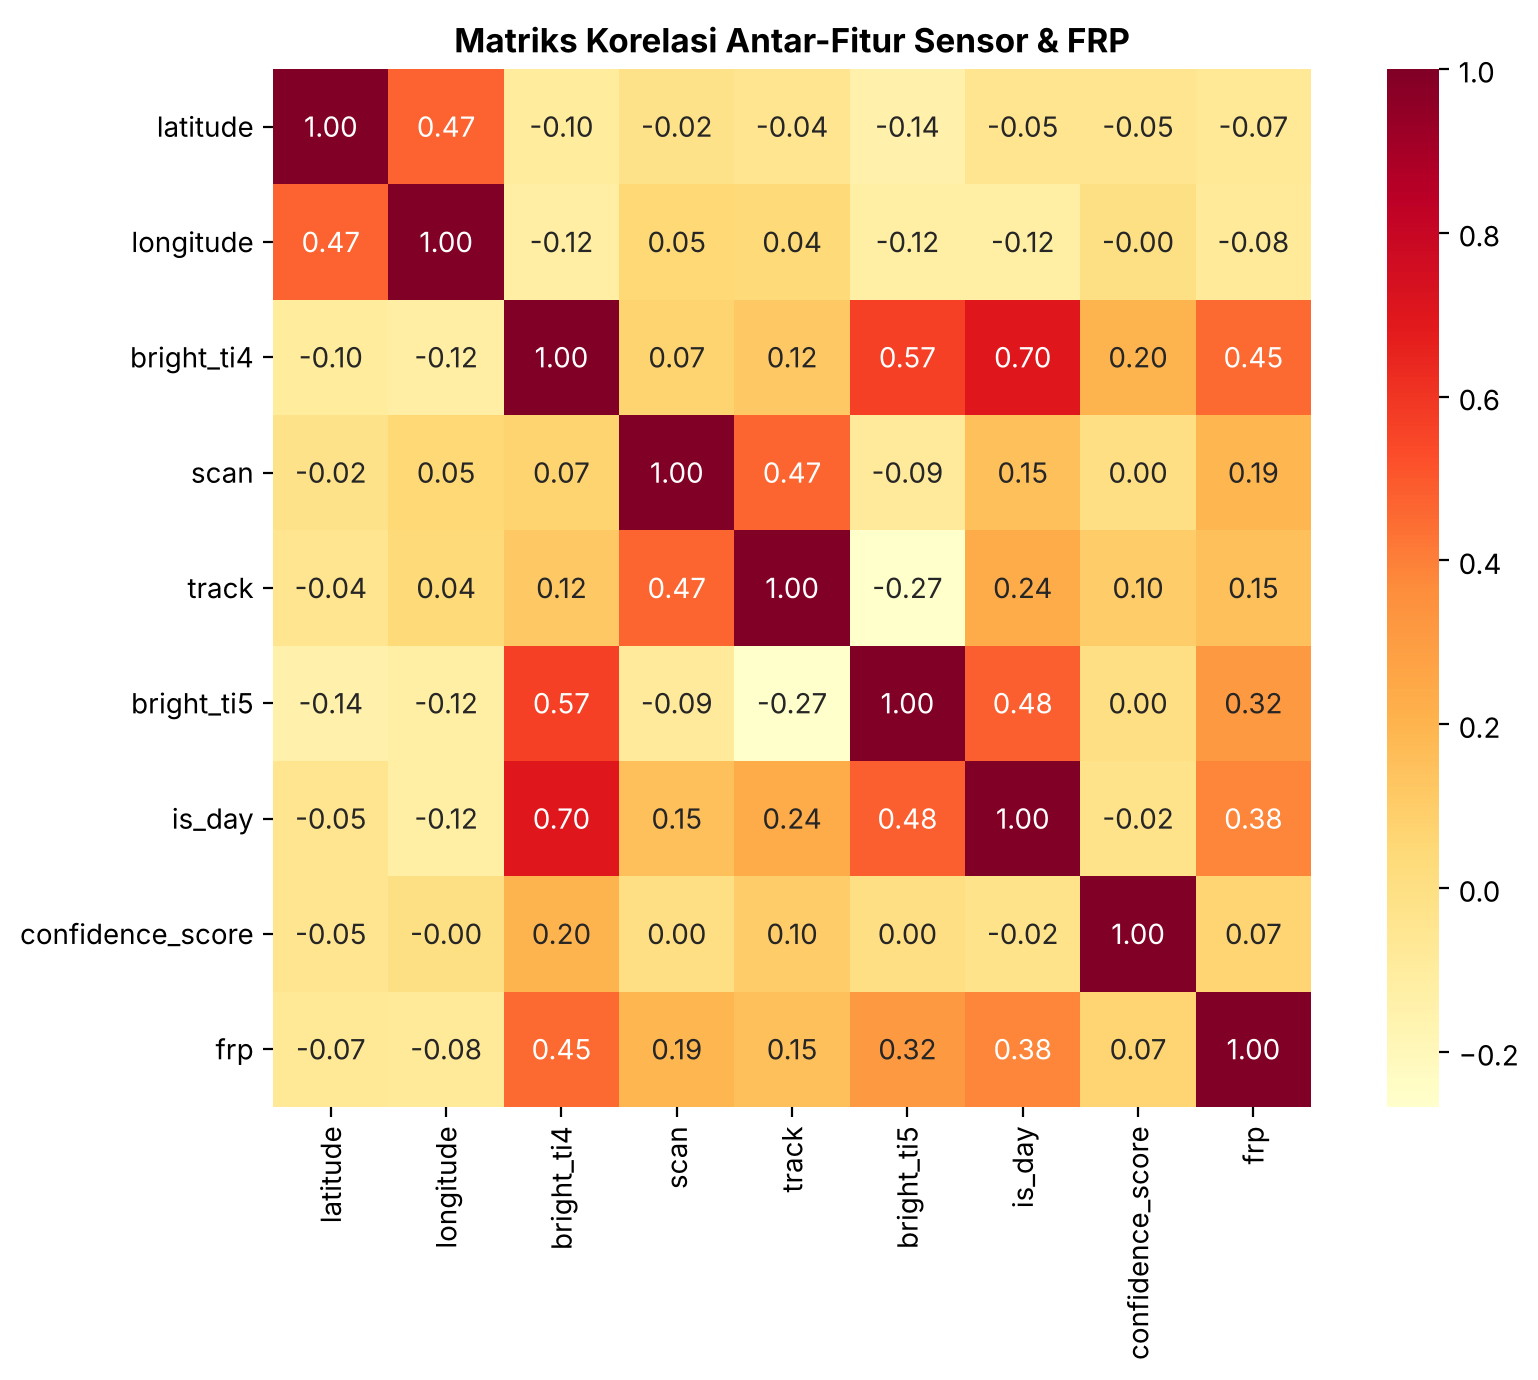

In [3]:
SENSOR_COLS = ['latitude', 'longitude', 'bright_ti4', 'scan', 'track',
               'bright_ti5', 'is_day', 'confidence_score', 'frp']

display(df[SENSOR_COLS].describe().T)

plt.figure(figsize=(9, 7))
sns.heatmap(df[SENSOR_COLS].corr(), annot=True, fmt='.2f', cmap='YlOrRd',
            cbar=True, square=True)
plt.title('Matriks Korelasi Antar-Fitur Sensor & FRP', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('matriks_korelasi_fitur.png', dpi=300, bbox_inches='tight')
plt.show()

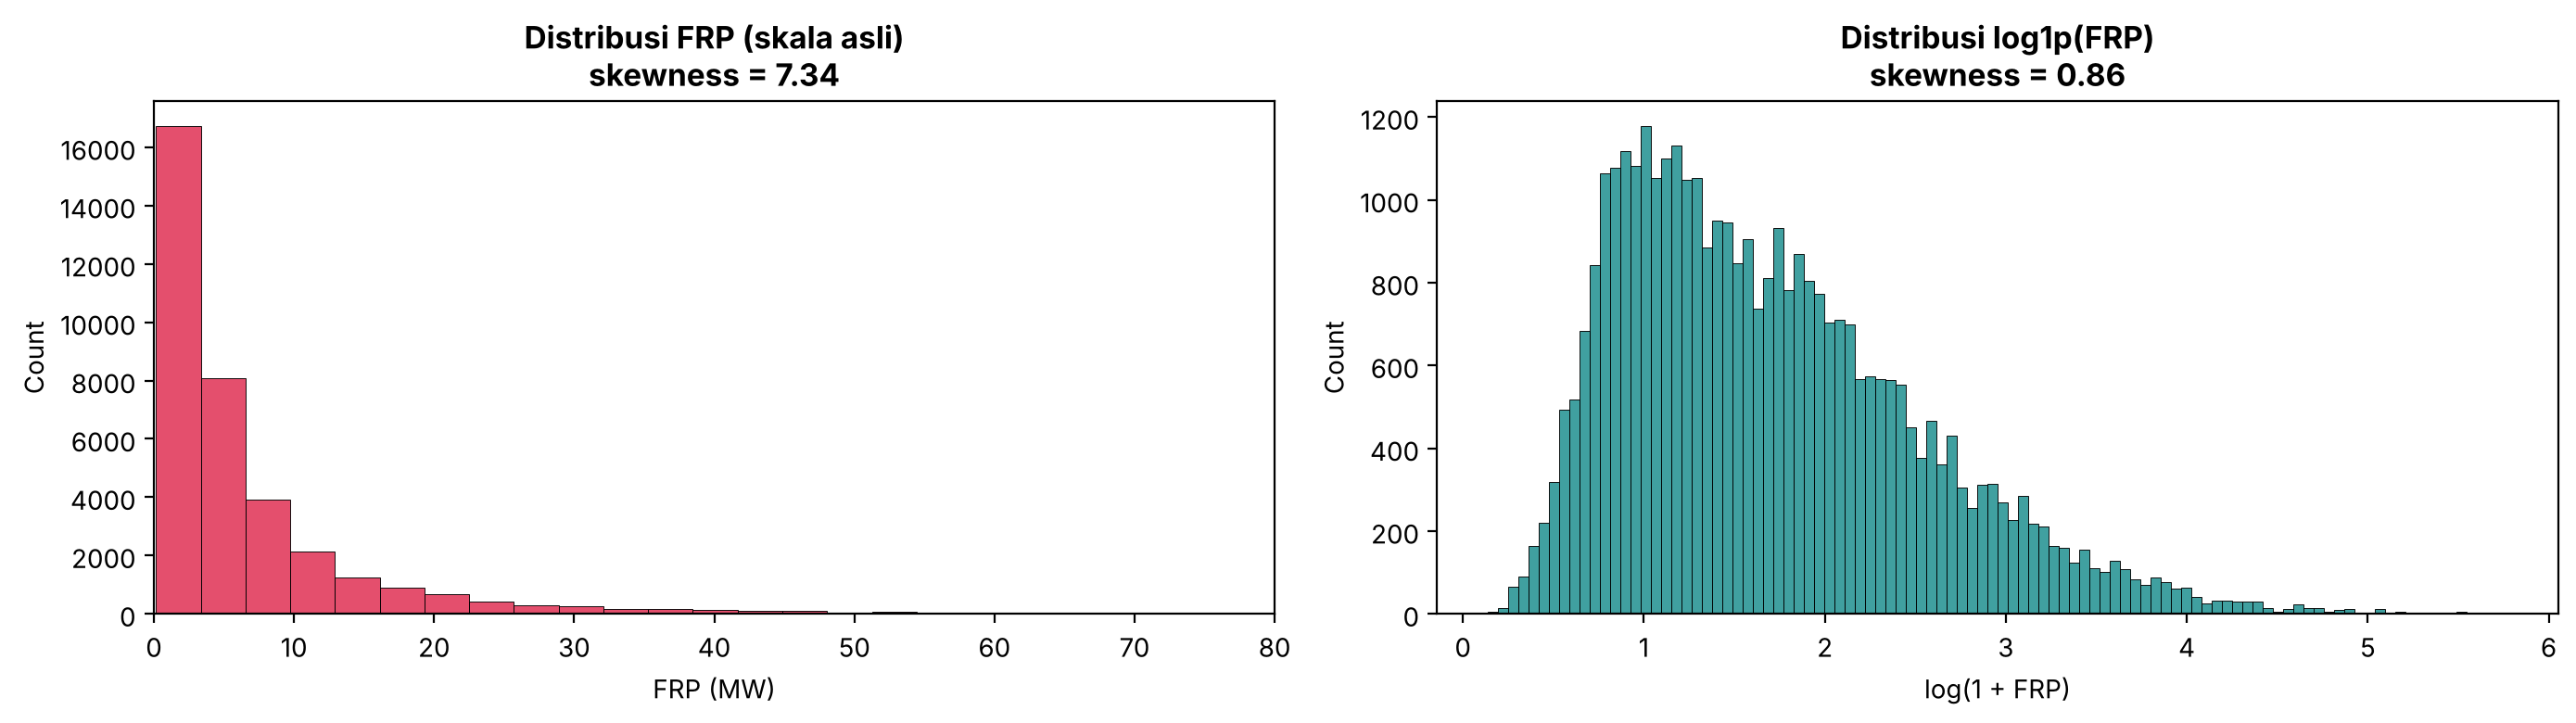

Median FRP : 3.69 MW
Mean FRP   : 7.36 MW
Maks FRP   : 319.51 MW
Sampel FRP >= 20 MW (CRITICAL): 2,676 (7.47%)


In [4]:
# Bukti skewness target: skala asli vs log1p
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['frp'], bins=100, ax=axes[0], color='crimson')
axes[0].set_xlim(0, 80)
axes[0].set_title(f'Distribusi FRP (skala asli)\nskewness = {df["frp"].skew():.2f}', fontweight='bold')
axes[0].set_xlabel('FRP (MW)')

sns.histplot(np.log1p(df['frp']), bins=100, ax=axes[1], color='teal')
axes[1].set_title(f'Distribusi log1p(FRP)\nskewness = {np.log1p(df["frp"]).skew():.2f}', fontweight='bold')
axes[1].set_xlabel('log(1 + FRP)')
plt.tight_layout()
plt.show()

print(f'Median FRP : {df["frp"].median():.2f} MW')
print(f'Mean FRP   : {df["frp"].mean():.2f} MW')
print(f'Maks FRP   : {df["frp"].max():.2f} MW')
print(f'Sampel FRP >= 20 MW (CRITICAL): {(df["frp"] >= 20).sum():,} '
      f'({(df["frp"] >= 20).mean() * 100:.2f}%)')

### 3b. Kualitas Data Sensor: Saturasi & *Fold-over* Kanal I4

Menurut dokumentasi produk VIIRS 375 m, nilai `bright_ti4` berada pada rentang **208–367 K**. Piksel api yang terlalu panas diberi nilai saturasi **367 K**, dan pada api yang sangat ekstrem nilai digitalnya **terlipat (*fold-over*)** sehingga tampak bersuhu sangat rendah (208 K). Piksel 208 K karenanya **bukan api dingin**, melainkan api yang melampaui batas ukur sensor.

Selain itu, FRP produk 375 m dihitung dari kanal M13 (750 m) yang tidak tersedia di CSV FIRMS, sehingga pada piksel jenuh fitur suhu I4 tidak lagi membawa informasi intensitas. Ini batas informasi yang menjelaskan kenapa kelas CRITICAL sulit diprediksi.

In [5]:
folded = df['bright_ti4'] <= 208.0
saturated = df['bright_ti4'] >= 367.0
print(f'Piksel I4 jenuh (367 K)   : {saturated.sum():,} ({saturated.mean() * 100:.2f}%) | '
      f'median FRP {df.loc[saturated, "frp"].median():.2f} MW')
print(f'Piksel I4 normal          : {(~saturated & ~folded).sum():,} | '
      f'median FRP {df.loc[~saturated & ~folded, "frp"].median():.2f} MW')
print(f'Piksel I4 terlipat (208 K): {folded.sum()} | FRP {df.loc[folded, "frp"].min():.2f}'
      f'–{df.loc[folded, "frp"].max():.2f} MW | confidence {sorted(df.loc[folded, "confidence_score"].unique())}')
display(df.loc[folded, ['latitude', 'longitude', 'bright_ti4', 'bright_ti5',
                        'confidence_score', 'frp', 'overpass']])

# Korelasi Pearson meremehkan hubungan monotonik pada target yang sangat menceng
display(pd.DataFrame({'Pearson': df[SENSOR_COLS].corr()['frp'],
                      'Spearman': df[SENSOR_COLS].corr(method='spearman')['frp']})
        .drop('frp').round(3))

Piksel I4 jenuh (367 K)   : 1,185 (3.31%) | median FRP 16.42 MW
Piksel I4 normal          : 34,631 | median FRP 3.51 MW
Piksel I4 terlipat (208 K): 10 | FRP 48.30–276.85 MW | confidence [np.int64(1)]


,latitude,longitude,bright_ti4,bright_ti5,confidence_score,frp,overpass
14233,-3.75215,116.18639,208.0,303.39,1,276.85,2026-10-22_D
14243,-3.74565,116.18549,208.0,315.36,1,276.85,2026-10-22_D
14249,-3.73944,116.18182,208.0,294.43,1,98.47,2026-10-22_D
14632,-2.48189,114.41513,208.0,313.22,1,154.31,2026-10-22_D
15391,-3.18792,111.96381,208.0,308.42,1,48.30,2026-10-22_D
15616,-3.12363,111.86930,208.0,308.37,1,56.96,2026-10-22_D
15664,-3.11482,111.92310,208.0,307.26,1,65.18,2026-10-22_D
16583,-2.67684,113.37987,208.0,305.50,1,105.45,2026-10-22_D
17113,-2.68006,113.37845,208.0,298.23,1,71.99,2026-10-22_D
31924,0.19339,116.61574,208.0,310.92,1,104.94,2026-10-26_D


,Pearson,Spearman
latitude,-0.069,-0.160
longitude,-0.079,-0.133
bright_ti4,0.451,0.830
scan,0.192,0.225
track,0.152,0.206
bright_ti5,0.315,0.549
is_day,0.384,0.652
confidence_score,0.067,0.077


### 4. Preprocessing: Feature Engineering, Splitting, & Normalisasi

**Fitur sensor dasar (8)**: `latitude`, `longitude`, `bright_ti4`, `scan`, `track`, `bright_ti5`, `is_day`, `confidence_score`. Untuk piksel terlipat, `bright_ti4` diset ke 367 K (melampaui saturasi) sebelum fitur turunan dihitung.

**Flag kualitas I4 (2)**

| Fitur | Definisi | Alasan |
|---|---|---|
| `ti4_folded` | `bright_ti4 == 208 K` | Api ekstrem yang membuat nilai digital I4 terlipat |
| `ti4_saturated` | `bright_ti4 >= 367 K` atau terlipat | Suhu I4 tidak lagi mengukur intensitas |

**Fitur turunan termal & geometris (7)**

| Fitur | Rumus | Alasan |
|---|---|---|
| `delta_t` | `bright_ti4 - bright_ti5` | Kontras suhu api terhadap latar (proksi energi radiasi) |
| `pixel_area` | `scan * track` | Luas piksel; FRP adalah daya total per piksel, jadi piksel lebih luas → FRP lebih besar |
| `ti4_day` | `bright_ti4 * is_day` | Interaksi suhu–waktu |
| `ti4_ti5_ratio` | `bright_ti4 / bright_ti5` | Kontras relatif terhadap kondisi latar |
| `delta_t_day` | `delta_t * is_day` | Kontras termal terkoreksi siang/malam |
| `conf_high` | `confidence_score == 3` | One-hot keyakinan deteksi tinggi |
| `conf_nominal` | `confidence_score == 2` | One-hot keyakinan nominal |

**Fitur temporal (3)** — dari `acq_time` (UTC)

| Fitur | Alasan |
|---|---|
| `hour_frac` | Fraksi waktu akuisisi dalam sehari (siklus diurnal) |
| `hour_sin`, `hour_cos` | Encoding siklik agar jam 23:59 dan 00:01 berdekatan |

`day_idx` **tidak dipakai sebagai fitur**: untuk tanggal baru nilainya selalu di luar rentang data latih.

**Fitur kerapatan hotspot (4)** — dihitung **per overpass** dari koordinat saja (tanpa target)

| Fitur | Alasan |
|---|---|
| `cell_density` | Jumlah hotspot di sel grid 0,5° pada overpass yang sama |
| `neigh_density` | Jumlah hotspot blok 3×3 sel (klaster kebakaran besar) |
| `overpass_total` | Total hotspot se-Kalimantan pada overpass tersebut |
| `neigh_density_norm` | Rasio klaster terhadap total overpass |

**Fitur klaster api (11)** — dari piksel api tetangga dalam radius 0,5 km dan 1 km pada overpass yang sama (tanpa target)

FRP produk 375 m dihitung dari piksel kanal M13 berukuran 750 m, yang mencakup beberapa piksel 375 m sekaligus. Karena itu jumlah, suhu, dan status saturasi piksel api di sekitarnya membawa informasi tentang total energi api yang tidak terlihat dari satu piksel saja.

| Fitur | Definisi |
|---|---|
| `mir_excess_area` | Kelebihan radiansi MIR 3,74 µm (hukum Planck: `L(T_I4) − L(T_I5)`) × luas piksel |
| `nb_count_{r}km` | Jumlah piksel api lain dalam radius *r* |
| `nb_max_ti4_{r}km`, `nb_mean_ti4_{r}km` | Suhu I4 maksimum dan rata-rata di sekitar piksel (termasuk dirinya) |
| `nb_sat_{r}km` | Jumlah piksel jenuh/terlipat dalam radius *r* |
| `nb_sum_excess_{r}km` | `log(1 + Σ mir_excess_area)` dalam radius *r* |

Versi awal menghitung kerapatan per tanggal UTC, sehingga titik api siang ikut "melihat" deteksi overpass malam ±12 jam kemudian (informasi masa depan). Per overpass, semua informasi sudah tersedia saat data satelit diterima.

**Total 35 fitur masukan.** Target dilatih sebagai `log1p(FRP)`; `StandardScaler` hanya di-*fit* pada data latih.

In [6]:
BASE_FEATURES = ['latitude', 'longitude', 'bright_ti4', 'scan', 'track',
                 'bright_ti5', 'is_day', 'confidence_score']
TARGET = 'frp'
I4_FOLD_K, I4_SAT_K = 208.0, 367.0
GRID_DEG = 0.5
CLUSTER_RADII_KM = (0.5, 1.0)
EARTH_RADIUS_KM = 6371.0

def fix_i4(frame):
    # Piksel terlipat (208 K) = api di atas batas ukur: tandai lalu set ke nilai saturasi.
    out = frame.copy()
    is_folded = frame['bright_ti4'] <= I4_FOLD_K
    out['ti4_folded'] = is_folded.astype(np.float32)
    out['ti4_saturated'] = (is_folded | (frame['bright_ti4'] >= I4_SAT_K)).astype(np.float32)
    out.loc[is_folded, 'bright_ti4'] = I4_SAT_K
    return out

def add_thermal_features(frame):
    out = frame.copy()
    out['delta_t'] = frame['bright_ti4'] - frame['bright_ti5']
    out['pixel_area'] = frame['scan'] * frame['track']
    out['ti4_day'] = frame['bright_ti4'] * frame['is_day']
    out['ti4_ti5_ratio'] = frame['bright_ti4'] / frame['bright_ti5']
    out['delta_t_day'] = out['delta_t'] * frame['is_day']
    out['conf_high'] = (frame['confidence_score'] == 3).astype(np.float32)
    out['conf_nominal'] = (frame['confidence_score'] == 2).astype(np.float32)
    return out

def add_temporal_features(frame):
    out = frame.copy()
    minutes = (frame['acq_time'] // 100) * 60 + (frame['acq_time'] % 100)
    out['hour_frac'] = minutes / 1440.0
    out['hour_sin'] = np.sin(2 * np.pi * out['hour_frac'])
    out['hour_cos'] = np.cos(2 * np.pi * out['hour_frac'])
    return out

def grid_cell(frame):
    return (np.floor(frame['latitude'] / GRID_DEG).astype(int).values,
            np.floor(frame['longitude'] / GRID_DEG).astype(int).values)

def build_density_tables(frame):
    # Kerapatan hotspot per (overpass, sel grid 0,5 derajat); hanya memakai koordinat & overpass.
    g = frame[['overpass', 'latitude', 'longitude']].copy()
    g['glat'], g['glon'] = grid_cell(g)
    keys = ['overpass', 'glat', 'glon']
    cell = g.groupby(keys).size().rename('cell_density').reset_index()

    frames = []
    for d_lat in (-1, 0, 1):
        for d_lon in (-1, 0, 1):
            tmp = cell.copy()
            tmp['glat'] = tmp['glat'] + d_lat
            tmp['glon'] = tmp['glon'] + d_lon
            frames.append(tmp)
    neigh = (pd.concat(frames).groupby(keys)['cell_density']
             .sum().rename('neigh_density').reset_index())
    total = g.groupby('overpass').size().rename('overpass_total').reset_index()
    return cell, neigh, total

def add_density_features(frame, tables):
    cell, neigh, total = tables
    keys = ['overpass', 'glat', 'glon']
    g = frame[['overpass', 'latitude', 'longitude']].copy()
    g['glat'], g['glon'] = grid_cell(g)
    g = (g.merge(cell, on=keys, how='left')
          .merge(neigh, on=keys, how='left')
          .merge(total, on='overpass', how='left'))
    cols = ['cell_density', 'neigh_density', 'overpass_total']
    g[cols] = g[cols].fillna(0)
    g['neigh_density_norm'] = (g['neigh_density'] / g['overpass_total'].replace(0, np.nan)).fillna(0)
    return g[DENSITY].reset_index(drop=True)

def planck_radiance(T, wavelength_um=3.74):
    # Radiansi benda hitam (W m^-2 sr^-1 um^-1) pada panjang gelombang kanal I4
    c1, c2 = 1.191042e8, 1.4387752e4
    return c1 / (wavelength_um ** 5 * (np.exp(c2 / (wavelength_um * T)) - 1.0))

NB_STATS = ['nb_count', 'nb_max_ti4', 'nb_mean_ti4', 'nb_sat', 'nb_sum_excess']

def add_cluster_features(frame):
    # Statistik piksel api tetangga dalam radius r pada overpass yang sama (hanya fitur masukan, tanpa target).
    f = frame.reset_index(drop=True)
    excess = ((planck_radiance(f['bright_ti4'].values) - planck_radiance(f['bright_ti5'].values))
              .clip(min=0) * f['pixel_area'].values)
    ti4, sat = f['bright_ti4'].values, f['ti4_saturated'].values
    out = {'mir_excess_area': excess}
    for r in CLUSTER_RADII_KM:
        for s in NB_STATS:
            out[f'{s}_{r}km'] = np.zeros(len(f))
    for _, idx in f.groupby('overpass').indices.items():
        coords = np.radians(f.loc[idx, ['latitude', 'longitude']].values)
        tree = BallTree(coords, metric='haversine')
        for r in CLUSTER_RADII_KM:
            for row, nb in zip(idx, tree.query_radius(coords, r=r / EARTH_RADIUS_KM)):
                nb = idx[nb]
                out[f'nb_count_{r}km'][row] = len(nb) - 1
                out[f'nb_max_ti4_{r}km'][row] = ti4[nb].max()
                out[f'nb_mean_ti4_{r}km'][row] = ti4[nb].mean()
                out[f'nb_sat_{r}km'][row] = sat[nb].sum()
                out[f'nb_sum_excess_{r}km'][row] = np.log1p(excess[nb].sum())
    return pd.DataFrame(out)[CLUSTER]

I4_FLAGS = ['ti4_folded', 'ti4_saturated']
THERMAL = ['delta_t', 'pixel_area', 'ti4_day', 'ti4_ti5_ratio',
           'delta_t_day', 'conf_high', 'conf_nominal']
TEMPORAL = ['hour_frac', 'hour_sin', 'hour_cos']
DENSITY = ['cell_density', 'neigh_density', 'overpass_total', 'neigh_density_norm']
CLUSTER = ['mir_excess_area'] + [f'{s}_{r}km' for r in CLUSTER_RADII_KM for s in NB_STATS]
FEATURES = BASE_FEATURES + I4_FLAGS + THERMAL + TEMPORAL + DENSITY + CLUSTER

df_fe = add_temporal_features(add_thermal_features(fix_i4(df))).reset_index(drop=True)
density_tables = build_density_tables(df_fe)
df_fe = pd.concat([df_fe, add_density_features(df_fe, density_tables), add_cluster_features(df_fe)], axis=1)

print(f'Jumlah fitur total: {len(FEATURES)}')
display(df_fe[CLUSTER + ['frp']].corr(method='spearman')['frp'].drop('frp').round(3).to_frame('Spearman vs FRP'))
df_fe[FEATURES].head()

Jumlah fitur total: 35


,Spearman vs FRP
mir_excess_area,0.827
nb_count_0.5km,0.181
nb_max_ti4_0.5km,0.828
nb_mean_ti4_0.5km,0.865
nb_sat_0.5km,0.342
nb_sum_excess_0.5km,0.781
nb_count_1.0km,0.226
nb_max_ti4_1.0km,0.787
nb_mean_ti4_1.0km,0.857
nb_sat_1.0km,0.405


,latitude,longitude,bright_ti4,scan,track,bright_ti5,is_day,confidence_score,ti4_folded,ti4_saturated,...,nb_count_0.5km,nb_max_ti4_0.5km,nb_mean_ti4_0.5km,nb_sat_0.5km,nb_sum_excess_0.5km,nb_count_1.0km,nb_max_ti4_1.0km,nb_mean_ti4_1.0km,nb_sat_1.0km,nb_sum_excess_1.0km
0,-2.97735,110.81212,335.33,0.41,0.37,303.09,1,2,0.0,0.0,...,1.0,335.33,334.90,0.0,0.295265,3.0,367.0,343.252500,1.0,0.751732
1,-2.97506,110.80424,367.00,0.41,0.37,307.10,1,3,0.0,1.0,...,0.0,367.00,367.00,1.0,0.471583,3.0,367.0,343.252500,1.0,0.751732
2,-2.97393,110.81159,334.47,0.41,0.37,306.52,1,1,0.0,0.0,...,1.0,335.33,334.90,0.0,0.295265,3.0,367.0,343.252500,1.0,0.751732
3,-2.97108,110.80739,336.21,0.41,0.37,307.31,1,2,0.0,0.0,...,0.0,336.21,336.21,0.0,0.160977,3.0,367.0,343.252500,1.0,0.751732
4,-2.96323,110.90434,341.82,0.41,0.37,302.79,1,2,0.0,0.0,...,1.0,346.00,343.91,0.0,0.429707,2.0,346.0,342.536667,0.0,0.565618


#### Splitting berkelompok (tanpa kebocoran)

Satu kebakaran terdeteksi sebagai banyak piksel 375 m yang bersebelahan dalam satu overpass, dan karena FRP dihitung dari piksel M13 750 m, piksel tetangga sering memiliki **FRP yang persis sama**. Split acak menaruh piksel-piksel kembar ini di data latih dan data uji sekaligus, sehingga skor uji terlalu optimistis (dibuktikan di bagian 8c).

Karena itu data dibagi per **kelompok = overpass × sel grid 0,5°**: seluruh piksel dalam satu kelompok selalu berada di sisi yang sama (latih, validasi, atau uji). Proporsi ±64% latih, 16% validasi, 20% uji.

In [7]:
X = df_fe[FEATURES].values.astype(np.float32)
y = df_fe[TARGET].values.astype(np.float64)

glat, glon = grid_cell(df_fe)
groups = (df_fe['overpass'] + '_' + pd.Series(glat).astype(str) + '_' + pd.Series(glon).astype(str)).values

def grouped_split(idx, test_size, seed=SEED):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    a, b = next(gss.split(idx, groups=groups[idx]))
    return idx[a], idx[b]

idx_all = np.arange(len(df_fe))
idx_train_full, idx_test = grouped_split(idx_all, test_size=0.2)
idx_train, idx_val = grouped_split(idx_train_full, test_size=0.2)
assert not (set(groups[idx_train]) & set(groups[idx_test])), 'kelompok bocor ke data uji'
assert not (set(groups[idx_train]) & set(groups[idx_val])), 'kelompok bocor ke data validasi'

X_train, X_val, X_test = X[idx_train], X[idx_val], X[idx_test]
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f'Jumlah kelompok (overpass x sel 0,5°): {len(np.unique(groups)):,}')
print(f'Jumlah Data Latih (Train) : {len(X_train):,} sampel')
print(f'Jumlah Data Validasi (Val): {len(X_val):,} sampel')
print(f'Jumlah Data Uji (Test)    : {len(X_test):,} sampel')
print(f'Bentuk X_train            : {X_train_scaled.shape}')

# Simpan dataset hasil preprocessing (35 fitur + target + label split) untuk dokumentasi & reproduksi
split_label = np.empty(len(df_fe), dtype=object)
split_label[idx_train], split_label[idx_val], split_label[idx_test] = 'train', 'val', 'test'
export = df_fe[['acq_date', 'acq_time', 'overpass'] + FEATURES + [TARGET]].copy()
export['acq_date'] = export['acq_date'].dt.strftime('%Y-%m-%d')
export['split'] = split_label
export.round(6).to_csv('data_karhutla_fitur_siap_latih.csv', index=False)
print(f'Dataset siap latih disimpan: data_karhutla_fitur_siap_latih.csv ({export.shape[0]:,} baris, {export.shape[1]} kolom)')

Jumlah kelompok (overpass x sel 0,5°): 1,514
Jumlah Data Latih (Train) : 24,228 sampel
Jumlah Data Validasi (Val): 4,869 sampel
Jumlah Data Uji (Test)    : 6,729 sampel
Bentuk X_train            : (24228, 35)


Dataset siap latih disimpan: data_karhutla_fitur_siap_latih.csv (35,826 baris, 40 kolom)


### 5. Arsitektur Jaringan Syaraf Tiruan (Deep Multilayer Perceptron)

Arsitektur dibuat fleksibel (jumlah & lebar hidden layer, fungsi aktivasi, BatchNorm, dropout) agar bisa dibandingkan pada tahap *hyperparameter tuning* (bagian 6b). Konfigurasi awal:

1. **Input Layer**: 35 neuron.
2. **Hidden Layer 1**: 256 neuron → `BatchNorm1d` → aktivasi → Dropout `0.2`.
3. **Hidden Layer 2**: 128 neuron → `BatchNorm1d` → aktivasi → Dropout `0.1`.
4. **Hidden Layer 3**: 64 neuron → `BatchNorm1d` → aktivasi → Dropout `0.05`.
5. **Output Layer**: 1 neuron `Linear` → memprediksi `log1p(FRP)`.

In [8]:
ACTIVATIONS = {'relu': nn.ReLU, 'gelu': nn.GELU, 'silu': nn.SiLU, 'tanh': nn.Tanh}

class KarhutlaJST(nn.Module):
    def __init__(self, input_dim, hidden=(256, 128, 64), drop=(0.2, 0.1, 0.05), act='gelu', batchnorm=True):
        super(KarhutlaJST, self).__init__()
        layers, prev = [], input_dim
        for i, h in enumerate(hidden):
            layers.append(nn.Linear(prev, h))
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(ACTIVATIONS[act]())
            if i < len(drop) and drop[i] > 0:
                layers.append(nn.Dropout(drop[i]))
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

model = KarhutlaJST(input_dim=X_train_scaled.shape[1]).to(device)
print(model)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\nTotal Parameter JST (konfigurasi awal): {total_params:,} bobot & bias.')

KarhutlaJST(
  (network): Sequential(
    (0): Linear(in_features=35, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): GELU(approximate='none')
    (7): Dropout(p=0.1, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): GELU(approximate='none')
    (11): Dropout(p=0.05, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
  )
)

Total Parameter JST (konfigurasi awal): 51,329 bobot & bias.


### 6. Pelatihan Model: Backpropagation, LR Scheduler, & Early Stopping

- **Loss**: MSE pada ruang `log1p(FRP)`.
- **Optimizer**: AdamW (`weight_decay = 1e-4`); learning rate & batch size ditentukan lewat tuning.
- **Scheduler**: `ReduceLROnPlateau` (faktor 0.5, patience 10).
- **Early stopping**: berhenti bila val loss tidak membaik 30 epoch; bobot terbaik dipulihkan.
- **Epoch maksimum**: 300.

Fungsi `train_jst` juga mendukung konfigurasi desain Tahap 1 (Adam, tanpa scheduler/early stopping, MSE pada FRP mentah) untuk studi ablasi di bagian 8d.

In [9]:
def train_jst(X_tr_scaled, y_tr, X_va_scaled, y_va, hidden=(256, 128, 64), drop=(0.2, 0.1, 0.05),
              act='gelu', batchnorm=True, lr=1e-3, weight_decay=1e-4, batch_size=128, log_target=True,
              optimizer_name='adamw', use_scheduler=True, epochs_max=300, patience=30, seed=SEED, verbose=True):
    set_seed(seed)
    net = KarhutlaJST(X_tr_scaled.shape[1], hidden, drop, act, batchnorm).to(device)
    to_target = np.log1p if log_target else (lambda v: v)
    train_ds = TensorDataset(torch.tensor(X_tr_scaled, dtype=torch.float32),
                             torch.tensor(to_target(y_tr), dtype=torch.float32).unsqueeze(1))
    val_ds = TensorDataset(torch.tensor(X_va_scaled, dtype=torch.float32),
                           torch.tensor(to_target(y_va), dtype=torch.float32).unsqueeze(1))
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=512, shuffle=False)

    criterion = nn.MSELoss()
    if optimizer_name == 'adamw':
        optimizer = optim.AdamW(net.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        optimizer = optim.Adam(net.parameters(), lr=lr)
    scheduler = (optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)
                 if use_scheduler else None)
    hist = {'train_loss': [], 'val_loss': []}
    best_val, best_state, bad_epochs = float('inf'), None, 0

    for epoch in range(1, epochs_max + 1):
        net.train()
        running = 0.0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            loss = criterion(net(batch_x), batch_y)
            loss.backward()
            optimizer.step()
            running += loss.item() * batch_x.size(0)
        epoch_train_loss = running / len(train_ds)

        net.eval()
        running = 0.0
        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                running += criterion(net(batch_x), batch_y).item() * batch_x.size(0)
        epoch_val_loss = running / len(val_ds)

        current_lr = optimizer.param_groups[0]['lr']
        if scheduler is not None:
            scheduler.step(epoch_val_loss)
        hist['train_loss'].append(epoch_train_loss)
        hist['val_loss'].append(epoch_val_loss)

        if epoch_val_loss < best_val - 1e-6:
            best_val, bad_epochs = epoch_val_loss, 0
            best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
        else:
            bad_epochs += 1

        if verbose and (epoch % 10 == 0 or epoch == 1):
            print(f'Epoch [{epoch:03d}/{epochs_max}] | Train MSE: {epoch_train_loss:.5f} | '
                  f'Val MSE: {epoch_val_loss:.5f} | LR: {current_lr:.2e} | no-improve: {bad_epochs}/{patience}')
        if patience and bad_epochs >= patience:
            if verbose:
                print(f'Early stopping pada epoch {epoch} (val loss terbaik {best_val:.5f}).')
            break

    if patience:                      # tanpa early stopping: pakai bobot epoch terakhir
        net.load_state_dict(best_state)
    net.log_target = log_target
    return net, hist

def jst_predict(net, Z_scaled, log_cap):
    net.eval()
    with torch.no_grad():
        out = net(torch.tensor(np.asarray(Z_scaled), dtype=torch.float32).to(device)).cpu().numpy().ravel()
    if getattr(net, 'log_target', True):
        return np.clip(np.expm1(np.minimum(out, log_cap)), 0, None)
    return np.clip(out, 0, None)

LOG_CAP = np.log1p(y_train.max())   # batas atas keluaran: FRP maksimum data latih

### 6b. Hyperparameter Tuning Bertahap

Pencarian dilakukan bertahap pada **data validasi** (kriteria: MSE validasi terbaik di ruang `log1p`, yaitu loss yang dioptimasi). Data uji tidak disentuh.

| Tahap | Yang dibandingkan |
|---|---|
| A | Fungsi aktivasi: ReLU, GELU, SiLU, Tanh |
| B | Arsitektur: 128-64-32, 256-128-64, 512-256-128, 256-256-128-64 |
| C | Learning rate (3e-3, 1e-3, 3e-4) dan batch size (64, 128, 512) |

Setiap tahap memakai pemenang tahap sebelumnya. Hasil disimpan ke `hasil_tuning_jst.csv`; set `RUN_TUNING = False` untuk memakai hasil tersimpan tanpa melatih ulang.

In [10]:
RUN_TUNING = True
ARCHS = {'128-64-32': ((128, 64, 32), (0.2, 0.1, 0.05)),
         '256-128-64': ((256, 128, 64), (0.2, 0.1, 0.05)),
         '512-256-128': ((512, 256, 128), (0.2, 0.1, 0.05)),
         '256-256-128-64': ((256, 256, 128, 64), (0.2, 0.1, 0.1, 0.05))}
cfg = dict(hidden=(256, 128, 64), drop=(0.2, 0.1, 0.05), act='gelu', lr=1e-3, batch_size=128)

if RUN_TUNING:
    tuning_rows, cache = [], {}

    def trial(stage, c):
        key = (c['act'], tuple(c['hidden']), c['lr'], c['batch_size'])
        if key not in cache:
            t0 = time.time()
            _, hist = train_jst(X_train_scaled, y_train, X_val_scaled, y_val, verbose=False, **c)
            cache[key] = min(hist['val_loss'])
            tuning_rows.append({'Tahap': stage, 'Aktivasi': c['act'], 'Arsitektur': '-'.join(map(str, c['hidden'])),
                                'Learning rate': c['lr'], 'Batch size': c['batch_size'],
                                'Val MSE (log)': cache[key], 'Epoch': len(hist['val_loss']),
                                'Detik': round(time.time() - t0)})
            print(f'{stage:22s} | {c["act"]:5s} | {"-".join(map(str, c["hidden"])):15s} | lr {c["lr"]:.0e} | '
                  f'batch {c["batch_size"]:3d} | val MSE (log) {cache[key]:.5f}')
        return cache[key]

    scores = {a: trial('A. Fungsi aktivasi', {**cfg, 'act': a}) for a in ['relu', 'gelu', 'silu', 'tanh']}
    cfg['act'] = min(scores, key=scores.get)

    scores = {n: trial('B. Arsitektur', {**cfg, 'hidden': h, 'drop': d}) for n, (h, d) in ARCHS.items()}
    cfg['hidden'], cfg['drop'] = ARCHS[min(scores, key=scores.get)]

    scores = {(lr, bs): trial('C. Learning rate & batch', {**cfg, 'lr': lr, 'batch_size': bs})
              for lr, bs in [(3e-3, 128), (1e-3, 128), (3e-4, 128), (1e-3, 64), (1e-3, 512)]}
    cfg['lr'], cfg['batch_size'] = min(scores, key=scores.get)

    tuning_df = pd.DataFrame(tuning_rows)
    tuning_df.to_csv('hasil_tuning_jst.csv', index=False)
else:
    tuning_df = pd.read_csv('hasil_tuning_jst.csv')
    best = tuning_df.loc[tuning_df['Val MSE (log)'].idxmin()]
    cfg['act'] = best['Aktivasi']
    cfg['hidden'], cfg['drop'] = ARCHS[best['Arsitektur']]
    cfg['lr'], cfg['batch_size'] = float(best['Learning rate']), int(best['Batch size'])

BEST_CFG = dict(cfg)
display(tuning_df.round(5))
print('Konfigurasi terbaik:', BEST_CFG)

A. Fungsi aktivasi     | relu  | 256-128-64      | lr 1e-03 | batch 128 | val MSE (log) 0.14807


A. Fungsi aktivasi     | gelu  | 256-128-64      | lr 1e-03 | batch 128 | val MSE (log) 0.14798


A. Fungsi aktivasi     | silu  | 256-128-64      | lr 1e-03 | batch 128 | val MSE (log) 0.14601


A. Fungsi aktivasi     | tanh  | 256-128-64      | lr 1e-03 | batch 128 | val MSE (log) 0.14877


B. Arsitektur          | silu  | 128-64-32       | lr 1e-03 | batch 128 | val MSE (log) 0.14618


B. Arsitektur          | silu  | 512-256-128     | lr 1e-03 | batch 128 | val MSE (log) 0.14786


... (3 outputs left out)

C. Learning rate & batch | silu  | 256-128-64      | lr 1e-03 | batch  64 | val MSE (log) 0.14848


C. Learning rate & batch | silu  | 256-128-64      | lr 1e-03 | batch 512 | val MSE (log) 0.14641


,Tahap,Aktivasi,Arsitektur,Learning rate,Batch size,Val MSE (log),Epoch,Detik
0,A. Fungsi aktivasi,relu,256-128-64,0.0010,128,0.14807,48,27
1,A. Fungsi aktivasi,gelu,256-128-64,0.0010,128,0.14798,79,47
2,A. Fungsi aktivasi,silu,256-128-64,0.0010,128,0.14601,79,45
3,A. Fungsi aktivasi,tanh,256-128-64,0.0010,128,0.14877,137,79
4,B. Arsitektur,silu,128-64-32,0.0010,128,0.14618,78,32
5,B. Arsitektur,silu,512-256-128,0.0010,128,0.14786,95,79
6,B. Arsitektur,silu,256-256-128-64,0.0010,128,0.14654,92,68
7,C. Learning rate & batch,silu,256-128-64,0.0030,128,0.14740,79,44
8,C. Learning rate & batch,silu,256-128-64,0.0003,128,0.14651,92,50
9,C. Learning rate & batch,silu,256-128-64,0.0010,64,0.14848,79,62


Konfigurasi terbaik: {'hidden': (256, 128, 64), 'drop': (0.2, 0.1, 0.05), 'act': 'silu', 'lr': 0.001, 'batch_size': 128}


### 6c. Pelatihan Model Final: Ensemble 5 Seed

Hasil satu kali pelatihan JST bergantung pada inisialisasi bobot acak (*seed*). Model final dilatih **5 kali dengan seed berbeda** memakai konfigurasi terbaik; prediksinya dirata-rata (ensemble) sehingga lebih stabil, dan sebaran skor antar-seed dilaporkan agar hasil tidak bergantung pada satu seed yang kebetulan baik.

In [11]:
N_SEEDS = 5
models, histories = [], []
print('Memulai proses pelatihan model JST final...')
for s in range(N_SEEDS):
    net, hist = train_jst(X_train_scaled, y_train, X_val_scaled, y_val, seed=SEED + s, verbose=(s == 0), **BEST_CFG)
    models.append(net)
    histories.append(hist)
    print(f'Seed {SEED + s}: {len(hist["val_loss"])} epoch | val MSE (log) terbaik {min(hist["val_loss"]):.5f}\n')

model, history = models[0], histories[0]
epochs_run = len(history['train_loss'])
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Parameter per model: {total_params:,} bobot & bias | arsitektur {BEST_CFG["hidden"]} | aktivasi {BEST_CFG["act"]}')

Memulai proses pelatihan model JST final...


Epoch [001/300] | Train MSE: 0.68857 | Val MSE: 0.20021 | LR: 1.00e-03 | no-improve: 0/30


Epoch [010/300] | Train MSE: 0.16508 | Val MSE: 0.15963 | LR: 1.00e-03 | no-improve: 1/30


Epoch [020/300] | Train MSE: 0.15423 | Val MSE: 0.15012 | LR: 1.00e-03 | no-improve: 1/30


Epoch [030/300] | Train MSE: 0.14893 | Val MSE: 0.14714 | LR: 1.00e-03 | no-improve: 0/30


Epoch [040/300] | Train MSE: 0.14430 | Val MSE: 0.15199 | LR: 1.00e-03 | no-improve: 10/30


... (4 outputs left out)

Seed 43: 67 epoch | val MSE (log) terbaik 0.14866



Seed 44: 61 epoch | val MSE (log) terbaik 0.14764



Seed 45: 98 epoch | val MSE (log) terbaik 0.14599



Seed 46: 104 epoch | val MSE (log) terbaik 0.14592

Parameter per model: 51,329 bobot & bias | arsitektur (256, 128, 64) | aktivasi silu


### 7. Evaluasi JST & Kalibrasi Isotonic

Model memprediksi `log1p(FRP)`; `expm1` mengembalikan ke MW. Dua pengaman dipakai:

1. **Batas atas keluaran**: keluaran log dibatasi pada `log1p(FRP maksimum data latih)`, sehingga input di luar distribusi tidak menghasilkan prediksi ribuan MW.
2. **Kalibrasi isotonic** di-*fit* pada data **validasi** (bukan test). Karena `expm1(E[log y]) ≤ E[y]` pada distribusi menceng, prediksi mentah cenderung *underestimate* **mean**; fungsi monotonik ini mengoreksi bias tersebut tanpa mengubah urutan prediksi.

In [12]:
def mse_of(a, b):
    return mean_squared_error(a, b)

def regression_metrics(y_true, p):
    m = mse_of(y_true, p)
    return {'MSE': m, 'RMSE': np.sqrt(m), 'MAE': mean_absolute_error(y_true, p), 'R2': r2_score(y_true, p),
            'R2 (log)': r2_score(np.log1p(y_true), np.log1p(np.clip(p, 0, None)))}

def predict_jst(frame_or_scaled, is_scaled=False):
    Z = frame_or_scaled if is_scaled else scaler.transform(frame_or_scaled)
    return np.mean([jst_predict(m, Z, LOG_CAP) for m in models], axis=0)

# Sebaran skor antar-seed (masing-masing dikalibrasi pada validasi)
seed_rows = []
for s, m in enumerate(models):
    pv, pt = jst_predict(m, X_val_scaled, LOG_CAP), jst_predict(m, X_test_scaled, LOG_CAP)
    iso_s = IsotonicRegression(out_of_bounds='clip').fit(pv, y_val)
    seed_rows.append({'Seed': SEED + s, **regression_metrics(y_test, iso_s.predict(pt))})
seed_df = pd.DataFrame(seed_rows)
print('SEBARAN SKOR JST PER SEED (data uji):')
display(seed_df.round(4))
display(seed_df.drop(columns='Seed').agg(['mean', 'std']).round(4))

# Ensemble 5 seed + kalibrasi isotonic
y_pred = predict_jst(X_test_scaled, is_scaled=True)
y_pred_val = predict_jst(X_val_scaled, is_scaled=True)
iso = IsotonicRegression(out_of_bounds='clip').fit(y_pred_val, y_val)
y_pred_cal = np.clip(iso.predict(y_pred), 0, None)
y_pred_val_cal = np.clip(iso.predict(y_pred_val), 0, None)

print(f'Prediksi mentah maksimum: val {y_pred_val.max():.1f} MW | test {y_pred.max():.1f} MW '
      f'(FRP aktual maksimum data latih {y_train.max():.1f} MW)')
print('\nPENGARUH KALIBRASI (data validasi):')
display(pd.DataFrame({
    'Tahap': ['JST ensemble (expm1 mentah)', 'JST ensemble + kalibrasi isotonic'],
    'MSE (val)': [f'{mse_of(y_val, y_pred_val):.4f}', f'{mse_of(y_val, y_pred_val_cal):.4f}'],
    'MAE (val)': [f'{mean_absolute_error(y_val, y_pred_val):.4f}',
                  f'{mean_absolute_error(y_val, y_pred_val_cal):.4f}'],
}))

jst_metrics = regression_metrics(y_test, y_pred_cal)
mse, rmse, mae, r2 = (jst_metrics[k] for k in ['MSE', 'RMSE', 'MAE', 'R2'])
print(f'\nHASIL EVALUASI JST (ENSEMBLE {N_SEEDS} SEED) PADA DATA UJI BERKELOMPOK (setelah kalibrasi):')
display(pd.DataFrame({
    'Metrik': ['Mean Squared Error (MSE)', 'Root Mean Squared Error (RMSE)',
               'Mean Absolute Error (MAE)', 'R-squared (R2 Score)', 'R-squared skala log1p'],
    'Nilai': [f'{mse:.4f}', f'{rmse:.4f} MW', f'{mae:.4f} MW', f'{r2:.4f}', f'{jst_metrics["R2 (log)"]:.4f}']
}))

SEBARAN SKOR JST PER SEED (data uji):


,Seed,MSE,RMSE,MAE,R2,R2 (log)
0,42,122.7216,11.0780,3.7958,0.3500,0.7157
1,43,122.8936,11.0857,3.7742,0.3491,0.7183
2,44,125.0889,11.1843,3.7934,0.3374,0.7178
3,45,121.2922,11.0133,3.7568,0.3575,0.7193
4,46,120.5963,10.9816,3.7625,0.3612,0.7196


,MSE,RMSE,MAE,R2,R2 (log)
mean,122.5185,11.0686,3.7765,0.3510,0.7181
std,1.7312,0.0781,0.0177,0.0092,0.0015


Prediksi mentah maksimum: val 139.3 MW | test 209.7 MW (FRP aktual maksimum data latih 319.5 MW)

PENGARUH KALIBRASI (data validasi):


,Tahap,MSE (val),MAE (val)
0,JST ensemble (expm1 mentah),56.2425,2.8067
1,JST ensemble + kalibrasi isotonic,49.3901,2.9174



HASIL EVALUASI JST (ENSEMBLE 5 SEED) PADA DATA UJI BERKELOMPOK (setelah kalibrasi):


,Metrik,Nilai
0,Mean Squared Error (MSE),121.8101
1,Root Mean Squared Error (RMSE),11.0368 MW
2,Mean Absolute Error (MAE),3.7579 MW
3,R-squared (R2 Score),0.3548
4,R-squared skala log1p,0.7210


In [13]:
# Analisis konsentrasi error: berapa persen sampel menyumbang mayoritas MSE?
sq_err = (y_test - y_pred_cal) ** 2
order = np.argsort(sq_err)[::-1]
share = np.cumsum(sq_err[order]) / sq_err.sum()
rows = []
for p in [0.005, 0.01, 0.014, 0.02, 0.05, 0.10]:
    k = max(int(len(y_test) * p), 1)
    rows.append({'Persentil sampel terburuk': f'{p * 100:.1f}%',
                 'Kontribusi terhadap MSE': f'{share[k - 1] * 100:.1f}%',
                 'Ambang error (MW)': f'{np.sqrt(sq_err[order][k - 1]):.2f}'})
display(pd.DataFrame(rows))
print(f'Median error absolut: {np.median(np.abs(y_test - y_pred_cal)):.3f} MW')
print(f'Rata-rata prediksi  : {y_pred_cal.mean():.3f} MW | rata-rata aktual: {y_test.mean():.3f} MW')

,Persentil sampel terburuk,Kontribusi terhadap MSE,Ambang error (MW)
0,0.5%,60.6%,68.18
1,1.0%,72.8%,45.25
2,1.4%,77.9%,33.78
3,2.0%,81.8%,25.75
4,5.0%,90.1%,13.43
5,10.0%,95.1%,8.90


Median error absolut: 1.053 MW
Rata-rata prediksi  : 7.095 MW | rata-rata aktual: 7.434 MW


### 8. Visualisasi Hasil Pembelajaran & Prediksi vs Aktual

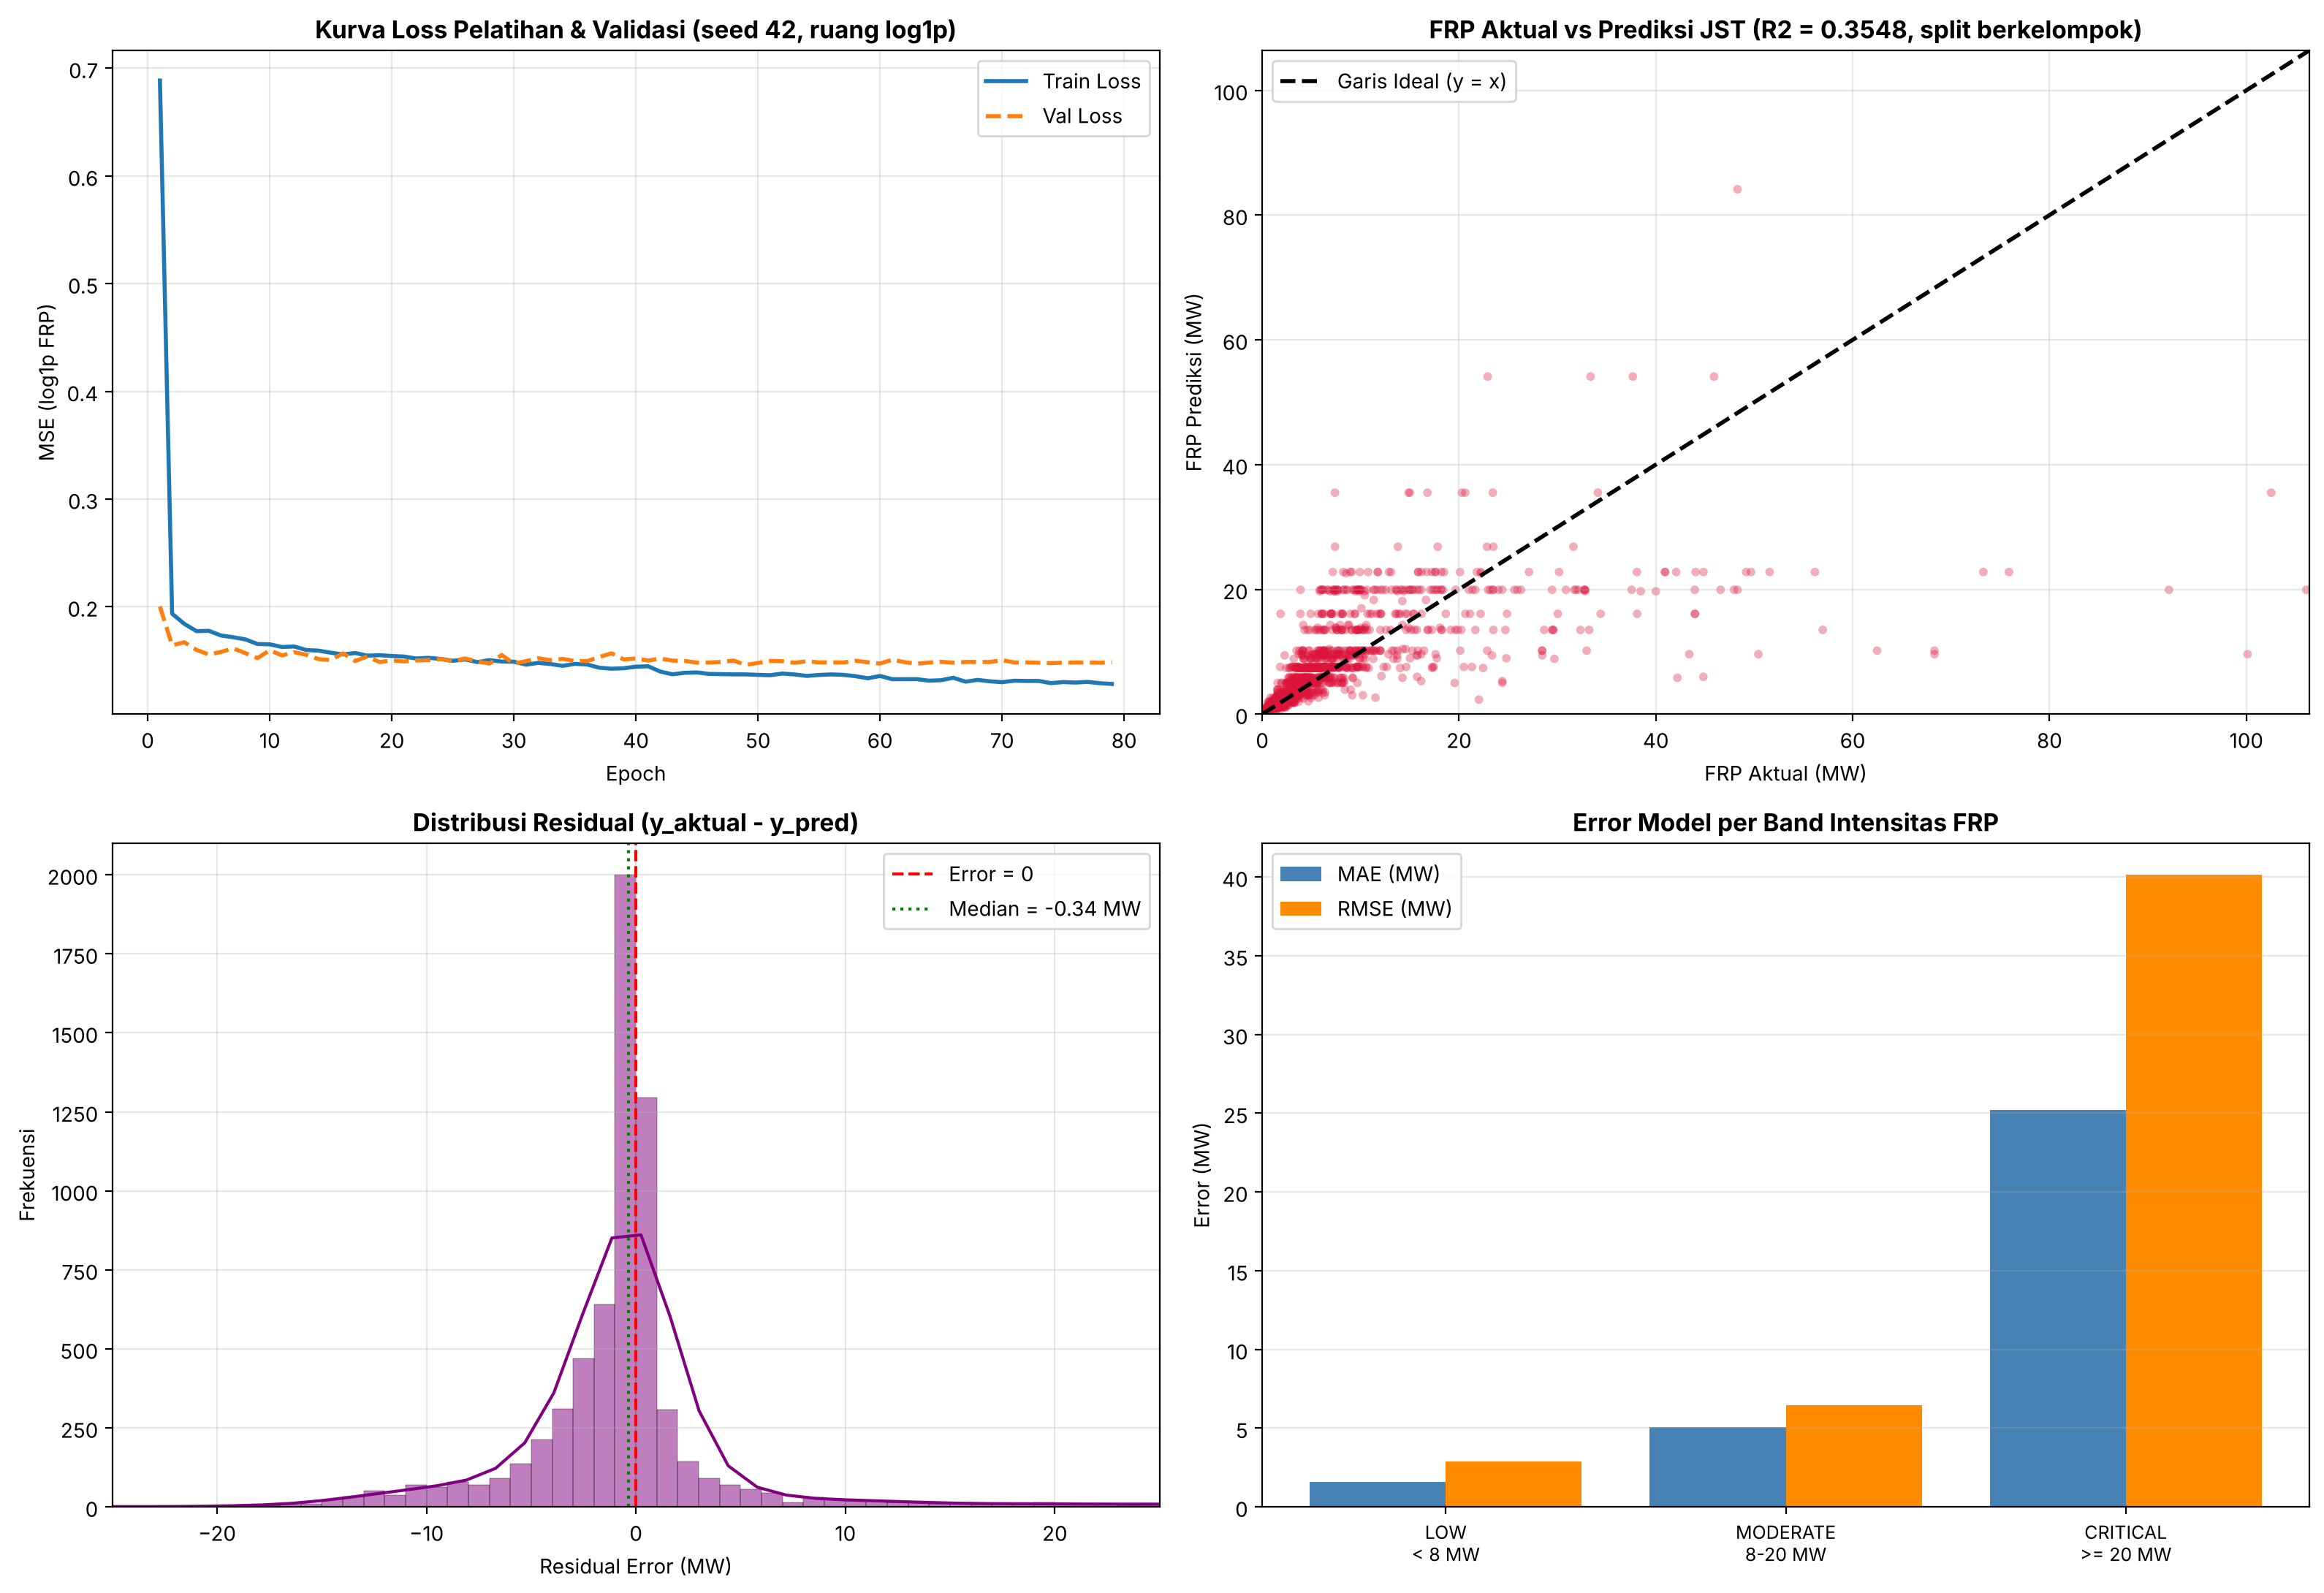

Grafik evaluasi disimpan ke: hasil_evaluasi_jst.png


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

ax = axes[0, 0]
ax.plot(range(1, epochs_run + 1), history['train_loss'], label='Train Loss', color='tab:blue', lw=2)
ax.plot(range(1, epochs_run + 1), history['val_loss'], label='Val Loss', color='tab:orange', lw=2, linestyle='--')
ax.set_title(f'Kurva Loss Pelatihan & Validasi (seed {SEED}, ruang log1p)', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('MSE (log1p FRP)')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[0, 1]
subset = np.random.RandomState(SEED).choice(len(y_test), size=min(1500, len(y_test)), replace=False)
ax.scatter(y_test[subset], y_pred_cal[subset], alpha=0.35, color='crimson', edgecolors='none', s=18)
lim = max(np.percentile(y_test[subset], 99.5), np.percentile(y_pred_cal[subset], 99.5)) * 1.05
ax.plot([0, lim], [0, lim], '--k', lw=2, label='Garis Ideal (y = x)')
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_title(f'FRP Aktual vs Prediksi JST (R2 = {r2:.4f}, split berkelompok)', fontweight='bold')
ax.set_xlabel('FRP Aktual (MW)'); ax.set_ylabel('FRP Prediksi (MW)')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1, 0]
residuals = y_test - y_pred_cal
sns.histplot(residuals, bins=np.arange(-25, 25.5, 1), kde=True, color='purple', ax=ax)
ax.axvline(0, color='red', linestyle='--', label='Error = 0')
ax.axvline(np.median(residuals), color='green', linestyle=':',
           label=f'Median = {np.median(residuals):.2f} MW')
ax.set_xlim(-25, 25)
ax.set_title('Distribusi Residual (y_aktual - y_pred)', fontweight='bold')
ax.set_xlabel('Residual Error (MW)'); ax.set_ylabel('Frekuensi')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1, 1]
bands = [('LOW\n< 8 MW', y_test < 8),
         ('MODERATE\n8-20 MW', (y_test >= 8) & (y_test < 20)),
         ('CRITICAL\n>= 20 MW', y_test >= 20)]
x_pos = np.arange(len(bands))
maes = [mean_absolute_error(y_test[m], y_pred_cal[m]) for _, m in bands]
rmses = [np.sqrt(mean_squared_error(y_test[m], y_pred_cal[m])) for _, m in bands]
ax.bar(x_pos - 0.2, maes, 0.4, label='MAE (MW)', color='steelblue')
ax.bar(x_pos + 0.2, rmses, 0.4, label='RMSE (MW)', color='darkorange')
ax.set_xticks(x_pos); ax.set_xticklabels([b for b, _ in bands], fontsize=9)
ax.set_title('Error Model per Band Intensitas FRP', fontweight='bold')
ax.set_ylabel('Error (MW)'); ax.legend(); ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('hasil_evaluasi_jst.png', dpi=300, bbox_inches='tight')
plt.show()
print('Grafik evaluasi disimpan ke: hasil_evaluasi_jst.png')

### 8b. Pembanding: Baseline, XGBoost & Ensemble

Untuk menilai seberapa besar kontribusi JST, dipakai beberapa pembanding dengan fitur dan split berkelompok yang sama:

- **Baseline konstan**: selalu memprediksi rata-rata FRP data latih (R² ≈ 0).
- **Regresi linear** pada `log1p(FRP)` + kalibrasi isotonic (model linear dengan perlakuan target yang sama).
- **XGBoost `reg:tweedie`** (varians 1,5) — *gradient boosting* yang kuat untuk data tabular dan target non-negatif yang menceng.
- **Ensemble JST + XGBoost**, bobot dipilih pada data validasi.

Model final dipilih **pada data validasi** (bukan test), sehingga angka uji tetap jujur.

In [15]:
def add_row(rows, name, p):
    rows.append({'Model': name, **regression_metrics(y_test, p)})

final_rows = []
add_row(final_rows, 'Baseline: rata-rata data latih', np.full(len(y_test), y_train.mean()))

lin = LinearRegression().fit(X_train_scaled, np.log1p(y_train))
lin_val = np.expm1(np.clip(lin.predict(X_val_scaled), 0, LOG_CAP))
lin_test = np.expm1(np.clip(lin.predict(X_test_scaled), 0, LOG_CAP))
iso_lin = IsotonicRegression(out_of_bounds='clip').fit(lin_val, y_val)
add_row(final_rows, 'Baseline: regresi linear (log1p) + isotonic', iso_lin.predict(lin_test))
add_row(final_rows, f'JST ensemble {N_SEEDS} seed + isotonic', y_pred_cal)

# Kandidat model final dinilai pada VALIDASI, bukan test: (MSE val, fungsi prediksi, prediksi test, prediksi val)
candidates = {
    f'JST ensemble {N_SEEDS} seed + isotonic': (
        mse_of(y_val, y_pred_val_cal),
        lambda Z: np.clip(iso.predict(predict_jst(Z)), 0, None),
        y_pred_cal, y_pred_val_cal,
    )
}

try:
    import xgboost as xgb

    XGB_PARAMS = dict(objective='reg:tweedie', tweedie_variance_power=1.5,
                      n_estimators=4000, learning_rate=0.03, max_depth=6,
                      subsample=0.8, colsample_bytree=0.8, min_child_weight=2, reg_lambda=1.0,
                      early_stopping_rounds=100, random_state=SEED, tree_method='hist',
                      device='cuda' if torch.cuda.is_available() else 'cpu')
    xgb_model = xgb.XGBRegressor(**XGB_PARAMS)
    xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

    y_pred_xgb = np.clip(xgb_model.predict(X_test), 0, None)
    y_pred_xgb_val = np.clip(xgb_model.predict(X_val), 0, None)
    add_row(final_rows, 'XGBoost (tweedie)', y_pred_xgb)

    # Ensemble: bobot dipilih pada validasi
    best_w, best_ens_val = 0.5, float('inf')
    for w in np.arange(0, 1.001, 0.05):
        v = mse_of(y_val, np.clip(w * y_pred_val_cal + (1 - w) * y_pred_xgb_val, 0, None))
        if v < best_ens_val:
            best_ens_val, best_w = v, w

    ens_name = f'Ensemble JST {best_w:.2f} + XGB {1 - best_w:.2f}'
    y_pred_ens = np.clip(best_w * y_pred_cal + (1 - best_w) * y_pred_xgb, 0, None)
    y_pred_ens_val = np.clip(best_w * y_pred_val_cal + (1 - best_w) * y_pred_xgb_val, 0, None)
    add_row(final_rows, ens_name, y_pred_ens)

    def _ens_predict(Z):
        jst_part = np.clip(iso.predict(predict_jst(Z)), 0, None)
        return np.clip(best_w * jst_part + (1 - best_w) * np.clip(xgb_model.predict(Z), 0, None), 0, None)

    candidates[ens_name] = (best_ens_val, _ens_predict, y_pred_ens, y_pred_ens_val)
except ImportError:
    xgb = None
    print('xgboost tidak terpasang, benchmark dilewati.')

best_name = min(candidates, key=lambda k: candidates[k][0])
best_val_mse, predict_final, y_pred_final, y_pred_final_val = candidates[best_name]

bench_df = pd.DataFrame(final_rows).sort_values('MSE')
print(f'Model final terpilih (MSE validasi terkecil = {best_val_mse:.4f}): {best_name}')
print('PERBANDINGAN MODEL (data uji berkelompok):')
display(bench_df.round(4))

Model final terpilih (MSE validasi terkecil = 49.3901): JST ensemble 5 seed + isotonic
PERBANDINGAN MODEL (data uji berkelompok):


,Model,MSE,RMSE,MAE,R2,R2 (log)
2,JST ensemble 5 seed + isotonic,121.8101,11.0368,3.7579,0.3548,0.7210
4,Ensemble JST 1.00 + XGB 0.00,121.8101,11.0368,3.7579,0.3548,0.7210
3,XGBoost (tweedie),128.3775,11.3304,3.7353,0.3200,0.7140
1,Baseline: regresi linear (log1p) + isotonic,133.3967,11.5497,4.0388,0.2934,0.6852
0,Baseline: rata-rata data latih,188.7944,13.7402,6.4160,-0.0000,-0.2870


In [16]:
# Evaluasi per-band untuk MODEL FINAL terpilih
bands = [('LOW (< 8 MW)', y_test < 8),
         ('MODERATE (8-20 MW)', (y_test >= 8) & (y_test < 20)),
         ('CRITICAL (>= 20 MW)', y_test >= 20)]

rows = []
for label, mask in bands:
    rows.append({'Band FRP': label, 'n Sampel': int(mask.sum()),
                 'Proporsi': f'{mask.mean() * 100:.1f}%',
                 'MAE (MW)': round(mean_absolute_error(y_test[mask], y_pred_final[mask]), 3),
                 'RMSE (MW)': round(np.sqrt(mean_squared_error(y_test[mask], y_pred_final[mask])), 3),
                 'Bias (MW)': round(np.mean(y_pred_final[mask] - y_test[mask]), 3)})
rows.append({'Band FRP': 'SELURUH TEST', 'n Sampel': len(y_test), 'Proporsi': '100.0%',
             'MAE (MW)': round(mean_absolute_error(y_test, y_pred_final), 3),
             'RMSE (MW)': round(np.sqrt(mean_squared_error(y_test, y_pred_final)), 3),
             'Bias (MW)': round(np.mean(y_pred_final - y_test), 3)})
band_df = pd.DataFrame(rows)
print(f'PERFORMA MODEL FINAL ({best_name}) PER-BAND:')
display(band_df)

PERFORMA MODEL FINAL (JST ensemble 5 seed + isotonic) PER-BAND:


,Band FRP,n Sampel,Proporsi,MAE (MW),RMSE (MW),Bias (MW)
0,LOW (< 8 MW),5111,76.0%,1.566,2.903,1.210
1,MODERATE (8-20 MW),1166,17.3%,5.047,6.443,1.817
2,CRITICAL (>= 20 MW),452,6.7%,25.218,40.138,-23.406
3,SELURUH TEST,6729,100.0%,3.758,11.037,-0.338


#### Ambang alarm CRITICAL dituning di data validasi

Prediksi regresi cenderung tertarik ke tengah, sehingga ambang 20 MW jarang terlewati dan banyak titik api CRITICAL lolos. Untuk keputusan mitigasi, yang penting adalah **recall CRITICAL** (titik api berbahaya tidak terlewat). Ambang alarm dipilih pada **data validasi** sebagai ambang terbesar yang masih memberi recall ≥ 70%, lalu diuji jujur pada data uji. Definisi kelas aktual tetap: CRITICAL = FRP ≥ 20 MW.

In [17]:
MODERATE_MW, CRITICAL_MW, TARGET_RECALL = 8.0, 20.0, 0.70

def crit_stats(y_true, p, thr):
    true_c, pred_c = y_true >= CRITICAL_MW, p >= thr
    tp = (true_c & pred_c).sum()
    return {'Recall CRITICAL': tp / max(true_c.sum(), 1),
            'Presisi CRITICAL': tp / max(pred_c.sum(), 1),
            'Porsi titik ditandai CRITICAL': pred_c.mean()}

def status(v, crit_thr=CRITICAL_MW):
    return np.where(v >= crit_thr, 2, np.where(v >= MODERATE_MW, 1, 0))

# ambang terbesar yang masih memberi recall >= TARGET_RECALL di VALIDASI
p_crit_val = np.sort(y_pred_final_val[y_val >= CRITICAL_MW])[::-1]
k = int(np.ceil(TARGET_RECALL * len(p_crit_val)))
CRITICAL_ALERT_MW = float(max(p_crit_val[k - 1], MODERATE_MW))

rows = []
for rule, thr in [('Ambang tetap 20 MW', CRITICAL_MW),
                  (f'Ambang alarm dituning di validasi ({CRITICAL_ALERT_MW:.2f} MW)', CRITICAL_ALERT_MW)]:
    acc = (status(y_test) == status(y_pred_final, thr)).mean()
    rows.append({'Aturan': rule, **crit_stats(y_test, y_pred_final, thr), 'Akurasi 3 kelas': acc})
print(f'Model final: {best_name}')
display(pd.DataFrame(rows).round(4))

labels = ['LOW', 'MODERATE', 'CRITICAL']
cm = confusion_matrix(status(y_test), status(y_pred_final, CRITICAL_ALERT_MW), labels=[0, 1, 2])
print(f'Confusion matrix data uji (ambang alarm {CRITICAL_ALERT_MW:.2f} MW):')
display(pd.DataFrame(cm, index=[f'Aktual {l}' for l in labels], columns=[f'Prediksi {l}' for l in labels]))

Model final: JST ensemble 5 seed + isotonic


,Aturan,Recall CRITICAL,Presisi CRITICAL,Porsi titik ditandai CRITICAL,Akurasi 3 kelas
0,Ambang tetap 20 MW,0.3097,0.5128,0.0406,0.8074
1,Ambang alarm dituning di validasi (16.08 MW),0.6615,0.3345,0.1329,0.7792


Confusion matrix data uji (ambang alarm 16.08 MW):


,Prediksi LOW,Prediksi MODERATE,Prediksi CRITICAL
Aktual LOW,4515,471,125
Aktual MODERATE,267,429,470
Aktual CRITICAL,40,113,299


### 8c. Uji Ketahanan: Seberapa Besar Skor Dipengaruhi Cara Split?

Tiga pengecekan:
1. **Bukti kebocoran**: persentase titik uji yang tetangga terdekatnya di data latih (overpass yang sama) memiliki FRP **identik**, untuk split acak vs split berkelompok.
2. **Validasi silang XGBoost** (cepat) dengan tiga skema: KFold acak (bocor), GroupKFold per overpass × sel, dan *forward-chaining* per hari (latih hanya dengan hari-hari sebelumnya, uji hari berikutnya).
3. **Uji waktu untuk JST**: latih hari 0–9, validasi hari 10–11, uji hari 12–14.

In [18]:
overpass_arr = df_fe['overpass'].values
coords_rad = np.radians(df_fe[['latitude', 'longitude']].values)

def share_identical_neighbour(idx_tr, idx_te):
    hits = []
    for ov in np.unique(overpass_arr[idx_te]):
        tr = idx_tr[overpass_arr[idx_tr] == ov]
        te = idx_te[overpass_arr[idx_te] == ov]
        if len(tr) == 0:
            hits.append(np.zeros(len(te), dtype=bool))
            continue
        _, j = BallTree(coords_rad[tr], metric='haversine').query(coords_rad[te], k=1)
        hits.append(y[tr][j[:, 0]] == y[te])
    return np.concatenate(hits).mean()

idx_rand_tr, idx_rand_te = train_test_split(idx_all, test_size=0.2, random_state=SEED)
print(f'Titik uji dengan tetangga latih ber-FRP identik | split acak      : '
      f'{share_identical_neighbour(idx_rand_tr, idx_rand_te) * 100:.1f}%')
print(f'Titik uji dengan tetangga latih ber-FRP identik | split berkelompok: '
      f'{share_identical_neighbour(idx_train_full, idx_test) * 100:.1f}%')

Titik uji dengan tetangga latih ber-FRP identik | split acak      : 29.6%


Titik uji dengan tetangga latih ber-FRP identik | split berkelompok: 0.4%


In [19]:
day_arr = df_fe['day_idx'].values

def robust_row(name, y_true, p):
    return {'Skema evaluasi': name, **regression_metrics(y_true, p),
            'Recall CRITICAL (20 MW)': crit_stats(y_true, p, CRITICAL_MW)['Recall CRITICAL']}

if xgb is not None:
    def fit_xgb_idx(tr, va):
        m = xgb.XGBRegressor(**XGB_PARAMS)
        m.fit(X[tr], y[tr], eval_set=[(X[va], y[va])], verbose=False)
        return m

    robust_rows = []
    oof = np.zeros(len(y))
    for tr, te in KFold(n_splits=5, shuffle=True, random_state=SEED).split(X):
        tr2, va = train_test_split(tr, test_size=0.2, random_state=SEED)
        oof[te] = np.clip(fit_xgb_idx(tr2, va).predict(X[te]), 0, None)
    robust_rows.append(robust_row('KFold acak 5-fold (bocor)', y, oof))

    oof = np.zeros(len(y))
    for tr, te in GroupKFold(n_splits=5).split(X, y, groups):
        tr2, va = grouped_split(tr, test_size=0.2)
        oof[te] = np.clip(fit_xgb_idx(tr2, va).predict(X[te]), 0, None)
    robust_rows.append(robust_row('GroupKFold 5-fold (overpass x sel 0,5°)', y, oof))

    y_fc, p_fc = [], []
    for day in range(6, day_arr.max() + 1):
        tr, va, te = (np.where(day_arr < day - 1)[0], np.where(day_arr == day - 1)[0],
                      np.where(day_arr == day)[0])
        if len(te) == 0 or len(va) == 0:
            continue
        y_fc.append(y[te])
        p_fc.append(np.clip(fit_xgb_idx(tr, va).predict(X[te]), 0, None))
    robust_rows.append(robust_row('Forward-chaining per hari (uji hari 6–14)',
                                  np.concatenate(y_fc), np.concatenate(p_fc)))
    print('VALIDASI SILANG XGBOOST — skor gabungan out-of-fold:')
    display(pd.DataFrame(robust_rows).round(4))

VALIDASI SILANG XGBOOST — skor gabungan out-of-fold:


,Skema evaluasi,MSE,RMSE,MAE,R2,R2 (log),Recall CRITICAL (20 MW)
0,KFold acak 5-fold (bocor),65.6089,8.0999,2.8370,0.5701,0.8139,0.5217
1,"GroupKFold 5-fold (overpass x sel 0,5°)",91.6398,9.5729,3.4079,0.3996,0.7555,0.4309
2,Forward-chaining per hari (uji hari 6–14),80.6943,8.9830,3.2560,0.3857,0.7284,0.2291


In [20]:
# Uji waktu untuk JST: latih hari 0-9, validasi hari 10-11, uji hari 12-14
t_tr = np.where(day_arr <= 9)[0]
t_va = np.where((day_arr >= 10) & (day_arr <= 11))[0]
t_te = np.where(day_arr >= 12)[0]

scaler_t = StandardScaler().fit(X[t_tr])
net_t, _ = train_jst(scaler_t.transform(X[t_tr]), y[t_tr], scaler_t.transform(X[t_va]), y[t_va],
                     verbose=False, **BEST_CFG)
cap_t = np.log1p(y[t_tr].max())
p_va_t = jst_predict(net_t, scaler_t.transform(X[t_va]), cap_t)
p_te_t = jst_predict(net_t, scaler_t.transform(X[t_te]), cap_t)
iso_t = IsotonicRegression(out_of_bounds='clip').fit(p_va_t, y[t_va])

temporal_rows = [robust_row('JST + isotonic (uji hari 12–14)', y[t_te], np.clip(iso_t.predict(p_te_t), 0, None))]
if xgb is not None:
    temporal_rows.append(robust_row('XGBoost (uji hari 12–14)', y[t_te],
                                    np.clip(fit_xgb_idx(t_tr, t_va).predict(X[t_te]), 0, None)))
print(f'UJI WAKTU: latih {len(t_tr):,} | validasi {len(t_va):,} | uji {len(t_te):,} sampel')
display(pd.DataFrame(temporal_rows).round(4))

UJI WAKTU: latih 32,992 | validasi 1,077 | uji 1,757 sampel


,Skema evaluasi,MSE,RMSE,MAE,R2,R2 (log),Recall CRITICAL (20 MW)
0,JST + isotonic (uji hari 12–14),43.7556,6.6148,3.0313,0.4054,0.7057,0.5124
1,XGBoost (uji hari 12–14),42.2381,6.4991,3.0165,0.4260,0.7114,0.3223


### 8d. Studi Ablasi: Dari Desain Tahap 1 ke Model Final

Setiap langkah menambahkan satu perubahan terhadap rancangan awal di dokumen Tahap 1, dilatih dan diuji pada split berkelompok yang sama, sehingga kontribusi tiap perubahan terlihat. Desain Tahap 1: 8 fitur, MLP 128-64-32 ReLU (dropout 0,2/0,1), Adam lr 0,001, batch 64, 30 epoch, loss MSE pada FRP mentah.

1. Desain Tahap 1 (8 fitur, ReLU, MSE FRP mentah, 30 epoch) selesai (14 detik)


2. + target log1p, LR scheduler & early stopping selesai (35 detik)


3. + kalibrasi isotonic selesai (31 detik)


4. + 16 fitur turunan (flag I4, termal, waktu, kerapatan) & arsitektur hasil tuning selesai (40 detik)


,Langkah,MSE,RMSE,MAE,R2,R2 (log)
0,"1. Desain Tahap 1 (8 fitur, ReLU, MSE FRP ment...",125.8890,11.2200,4.5749,0.3332,0.5680
1,"2. + target log1p, LR scheduler & early stopping",133.2929,11.5453,3.7521,0.2940,0.6737
2,3. + kalibrasi isotonic,131.9647,11.4876,4.0616,0.3010,0.6470
3,"4. + 16 fitur turunan (flag I4, termal, waktu,...",131.2908,11.4582,4.1287,0.3046,0.6420
4,"5. + 11 fitur klaster api (35 fitur, 1 seed)",122.7216,11.0780,3.7958,0.3500,0.7157
5,6. + ensemble 5 seed (JST final),121.8101,11.0368,3.7579,0.3548,0.7210


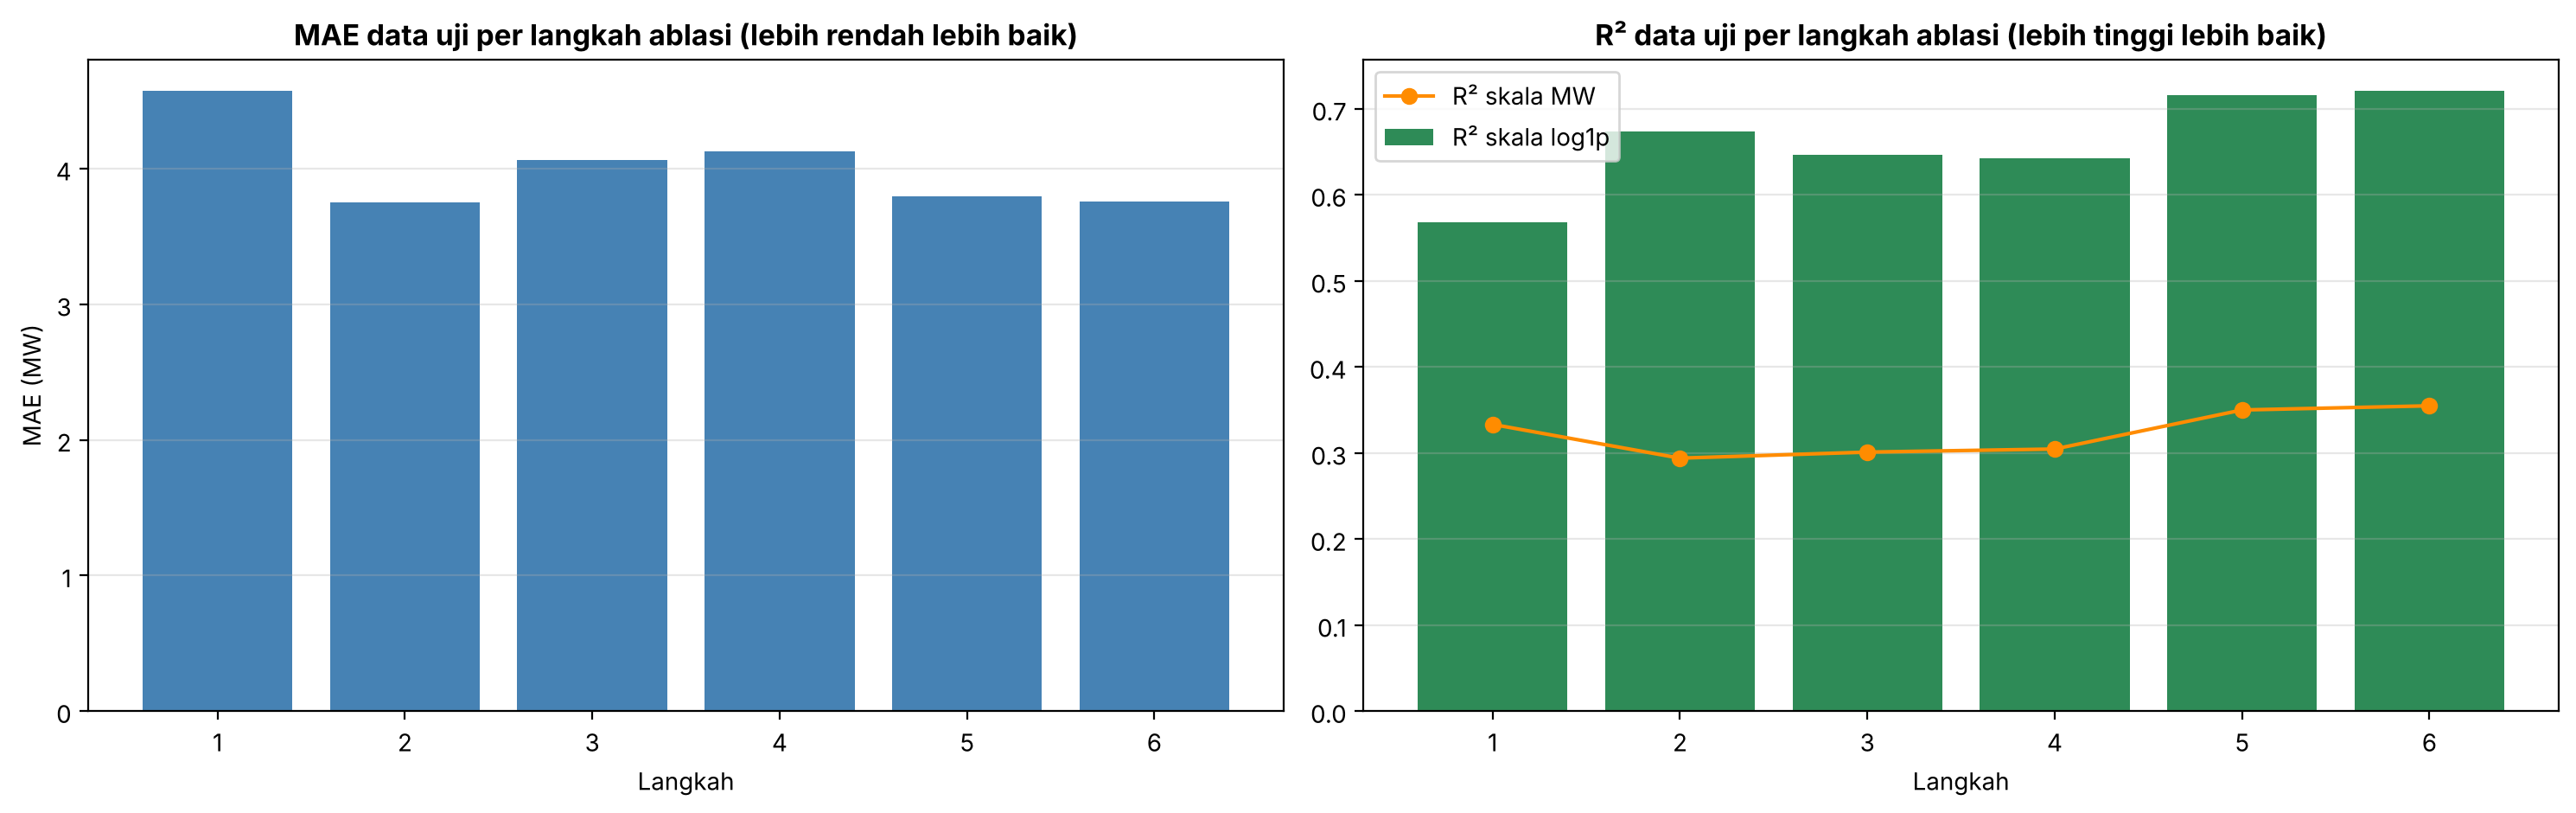

In [21]:
idx8 = [FEATURES.index(c) for c in BASE_FEATURES]
idx24 = [FEATURES.index(c) for c in FEATURES if c not in CLUSTER]
STAGE1 = dict(hidden=(128, 64, 32), drop=(0.2, 0.1, 0.0), act='relu', batchnorm=False,
              lr=1e-3, batch_size=64, optimizer_name='adam')

def ablation_run(cols, calibrate, **c):
    sc = StandardScaler().fit(X_train[:, cols])
    net, _ = train_jst(sc.transform(X_train[:, cols]), y_train, sc.transform(X_val[:, cols]), y_val, verbose=False, **c)
    pv = jst_predict(net, sc.transform(X_val[:, cols]), LOG_CAP)
    pt = jst_predict(net, sc.transform(X_test[:, cols]), LOG_CAP)
    return IsotonicRegression(out_of_bounds='clip').fit(pv, y_val).predict(pt) if calibrate else pt

steps = [
    ('1. Desain Tahap 1 (8 fitur, ReLU, MSE FRP mentah, 30 epoch)', idx8, False,
     {**STAGE1, 'log_target': False, 'use_scheduler': False, 'epochs_max': 30, 'patience': 0}),
    ('2. + target log1p, LR scheduler & early stopping', idx8, False, STAGE1),
    ('3. + kalibrasi isotonic', idx8, True, STAGE1),
    ('4. + 16 fitur turunan (flag I4, termal, waktu, kerapatan) & arsitektur hasil tuning', idx24, True, BEST_CFG),
]
ablation_rows = []
for name, cols, cal, c in steps:
    t0 = time.time()
    ablation_rows.append({'Langkah': name, **regression_metrics(y_test, ablation_run(cols, cal, **c))})
    print(f'{name} selesai ({time.time() - t0:.0f} detik)')

pv0, pt0 = jst_predict(models[0], X_val_scaled, LOG_CAP), jst_predict(models[0], X_test_scaled, LOG_CAP)
ablation_rows.append({'Langkah': '5. + 11 fitur klaster api (35 fitur, 1 seed)',
                      **regression_metrics(y_test, IsotonicRegression(out_of_bounds='clip').fit(pv0, y_val).predict(pt0))})
ablation_rows.append({'Langkah': f'6. + ensemble {N_SEEDS} seed (JST final)', **regression_metrics(y_test, y_pred_cal)})

ablation_df = pd.DataFrame(ablation_rows)
ablation_df.to_csv('hasil_ablasi_jst.csv', index=False)
display(ablation_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
short = [r['Langkah'].split(' ')[0].rstrip('.') for r in ablation_rows]
axes[0].bar(short, ablation_df['MAE'], color='steelblue')
axes[0].set_title('MAE data uji per langkah ablasi (lebih rendah lebih baik)', fontweight='bold')
axes[0].set_xlabel('Langkah'); axes[0].set_ylabel('MAE (MW)')
axes[1].bar(short, ablation_df['R2 (log)'], color='seagreen', label='R² skala log1p')
axes[1].plot(short, ablation_df['R2'], 'o-', color='darkorange', label='R² skala MW')
axes[1].set_title('R² data uji per langkah ablasi (lebih tinggi lebih baik)', fontweight='bold')
axes[1].set_xlabel('Langkah'); axes[1].legend()
for ax in axes:
    ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('hasil_ablasi_jst.png', dpi=300, bbox_inches='tight')
plt.show()

### 9. Simulasi Inferensi: Estimasi Keganasan Titik Api Baru untuk Mitigasi Lapangan

Titik api baru diperlakukan seperti deteksi pada **overpass terakhir** (siang atau malam sesuai `is_day`): fitur termal dan temporal dibentuk dengan fungsi yang sama seperti saat pelatihan, sedangkan fitur kerapatan dan klaster api dihitung ulang bersama seluruh deteksi overpass tersebut. `acq_time` FIRMS dalam **UTC**; S-NPP melintasi Kalimantan sekitar 04–07 UTC (siang, ±11–14 WIB) dan 16–19 UTC (malam, ±23–02 WIB), jadi contoh di bawah memakai jam overpass yang realistis.

Kategori memakai **ambang alarm CRITICAL hasil tuning** pada data validasi.

In [22]:
sample_hotspots = pd.DataFrame([
    {'lokasi': 'Katingan (Hutan Gambut Pekat)', 'latitude': -2.05, 'longitude': 113.35, 'bright_ti4': 365.2, 'scan': 0.40, 'track': 0.38, 'bright_ti5': 304.5, 'is_day': 1, 'confidence_score': 3, 'acq_time': 605},
    {'lokasi': 'Seruyan (Dekat Pemukiman)', 'latitude': -2.52, 'longitude': 112.21, 'bright_ti4': 342.1, 'scan': 0.48, 'track': 0.42, 'bright_ti5': 298.0, 'is_day': 1, 'confidence_score': 2, 'acq_time': 625},
    {'lokasi': 'Ketapang (Titik Api Malam Hari)', 'latitude': -1.82, 'longitude': 110.15, 'bright_ti4': 324.6, 'scan': 0.55, 'track': 0.45, 'bright_ti5': 291.3, 'is_day': 0, 'confidence_score': 1, 'acq_time': 1750}
])

last_overpass = {flag: sorted(o for o in df_fe['overpass'].unique() if o.endswith('_' + flag))[-1]
                 for flag in ('D', 'N')}
sample_hotspots['overpass'] = np.where(sample_hotspots['is_day'] == 1, last_overpass['D'], last_overpass['N'])

sim = add_temporal_features(add_thermal_features(fix_i4(sample_hotspots))).reset_index(drop=True)
pool_cols = ['overpass', 'latitude', 'longitude', 'bright_ti4', 'bright_ti5', 'pixel_area', 'ti4_saturated']
pool = pd.concat([df_fe[pool_cols], sim[pool_cols]], ignore_index=True)
sim = pd.concat([sim,
                 add_density_features(sim, build_density_tables(pool)),
                 add_cluster_features(pool).iloc[-len(sim):].reset_index(drop=True)], axis=1)

X_sim = sim[FEATURES].values.astype(np.float32)
pred_frp = predict_final(X_sim)
sample_hotspots['Prediksi FRP (MW)'] = np.round(pred_frp, 2)

def kategori_bahaya(frp_val):
    if frp_val >= CRITICAL_ALERT_MW:
        return 'CRITICAL / TINGGI (Prioritaskan Water Bombing Helikopter)'
    elif frp_val >= MODERATE_MW:
        return 'MODERATE / SEDANG (Tim Manggala Agni Darat)'
    else:
        return 'LOW / RINGAN (Pemantauan Satelit Berkala)'

sample_hotspots['Status & Rekomendasi Mitigasi'] = sample_hotspots['Prediksi FRP (MW)'].apply(kategori_bahaya)
print(f'Model: {best_name} | ambang alarm CRITICAL: {CRITICAL_ALERT_MW:.2f} MW')
display(sample_hotspots[['lokasi', 'latitude', 'longitude', 'bright_ti4', 'acq_time', 'overpass',
                         'Prediksi FRP (MW)', 'Status & Rekomendasi Mitigasi']])

Model: JST ensemble 5 seed + isotonic | ambang alarm CRITICAL: 16.08 MW


,lokasi,latitude,longitude,bright_ti4,acq_time,overpass,Prediksi FRP (MW),Status & Rekomendasi Mitigasi
0,Katingan (Hutan Gambut Pekat),-2.05,113.35,365.2,605,2026-11-01_D,19.93,CRITICAL / TINGGI (Prioritaskan Water Bombing ...
1,Seruyan (Dekat Pemukiman),-2.52,112.21,342.1,625,2026-11-01_D,7.56,LOW / RINGAN (Pemantauan Satelit Berkala)
2,Ketapang (Titik Api Malam Hari),-1.82,110.15,324.6,1750,2026-11-01_N,7.39,LOW / RINGAN (Pemantauan Satelit Berkala)


### 10. Kesimpulan

1. **JST final** — MLP 35-256-128-64-1 dengan aktivasi SiLU, BatchNorm, dropout, ensemble 5 seed, dan kalibrasi isotonic — memberi hasil terbaik pada data uji berkelompok: MSE 121,81; RMSE 11,04 MW; MAE 3,76 MW; R² 0,355; R² skala log 0,721. JST mengungguli XGBoost (MSE 128,38; R² 0,320) dan regresi linear (R² 0,293), dengan MAE hampir sama dengan XGBoost (3,76 vs 3,74 MW). Pada pemilihan di data validasi, bobot XGBoost dalam ensemble JST+XGBoost adalah 0.
2. **Fitur klaster api adalah perbaikan terbesar.** Studi ablasi: menambahkan 11 fitur klaster menurunkan MAE dari 4,13 ke 3,80 MW dan menaikkan R² dari 0,305 ke 0,350 (skala log 0,642 → 0,716). Alasannya fisis: FRP dihitung dari piksel M13 750 m yang mencakup beberapa piksel 375 m, sehingga piksel api di sekitarnya membawa informasi energi total.
3. **Hyperparameter tuning** menunjukkan selisih antar-konfigurasi kecil (MSE validasi log 0,1460–0,1488, < 2%). Arsitektur bukan hambatan utama; informasi pada fitur yang paling menentukan.
4. **Desain Tahap 1** (MSE pada FRP mentah) punya MSE lebih rendah (125,89) daripada langkah 2–4, tetapi MAE terburuk (4,57 MW) dan R² skala log terendah (0,568): loss MSE mentah memusatkan model pada segelintir api ekstrem. Target `log1p` membuat api tipikal diprediksi jauh lebih baik. Model final terbaik pada MSE, R², dan R² skala log; MAE-nya setara dengan langkah 2 (3,76 vs 3,75 MW) karena kalibrasi isotonic menggeser prediksi ke arah rata-rata, yang menurunkan MSE tetapi sedikit menaikkan MAE.
5. **Stabil antar-seed**: R² 0,351 ± 0,009 dan MAE 3,777 ± 0,018 MW untuk 5 seed.
6. **Untuk mitigasi**, ambang alarm 16,08 MW (dituning di validasi) menangkap 66,2% titik api CRITICAL (31,0% dengan ambang 20 MW), dengan presisi 33,4% dan 13,3% titik ditandai; akurasi 3 kelas 77,9%.
7. **Evaluasi jujur penting**: XGBoost dengan split acak mendapat R² 0,570, sedangkan GroupKFold 0,400 dan *forward-chaining* 0,386. Pada uji waktu (hari 12–14), JST mendapat R² 0,405.

**Batasan yang tersisa** (butuh data baru, bukan tuning):
- FRP produk 375 m dihitung dari kanal M13 (750 m) yang tidak ada di CSV FIRMS, dan 3,3% piksel I4 jenuh pada 367 K; kelas CRITICAL masih *underestimate* (bias −23,4 MW).
- Hanya 15 hari pada satu musim dan satu satelit (S-NPP).
- Belum ada data cuaca, gambut/tutupan lahan, atau riwayat FRP dari overpass sebelumnya.

**Arah pengembangan**: tambahkan deteksi NOAA-20/NOAA-21 (lebih banyak overpass per hari dan riwayat per lokasi), data cuaca (mis. ERA5), peta gambut, serta periode lebih panjang. Evaluasi selalu dengan skema berkelompok atau berurutan waktu.